# UP2 evidence notebook: the 17 counted items

**Team M001, Real-Time Edge Digital Twin for Bearing Fault Diagnosis and RUL Prediction in OH-2 Centrifugal Pumps.**
ICS owner of the models: Muhammad Jaddoua. Update Presentation 2 (in class with coach Dr. Uthman Baroudi, 25/26 Oct 2026).

Every number below is **recomputed in a cell**: from data and saved predictions on disk, from the deployed ONNX engine run live, or by a live
program (`dotnet test`, the ASP.NET backend, the SignalR measurement client). Each cell records its result in a registry; the banner, the
scorecard and the master table are built from that registry, so they cannot drift from the evidence. A missing input shows a grey
**MISSING** badge instead of crashing, and the item falls back to the evidence that remains.

**Data basis.** Synthetic and simulated data are a **coach-approved** substitute for rig data (the sensor parts may not arrive in time).
Every number carries a provenance tag: `[SYNTHETIC]` (aiengine/synth_v3), `[SIMULATION]` (COE rig simulator, FE twin), `[MEASURED host]`
(this PC, not the STM32 or the final server), `[CALCULATED]`, `[MEASURED on <public dataset>]` (PPR history). A live-recomputed simulation is
Rank 9 "working simulation demo" by *form*; it does not become physical-prototype evidence.

<details><summary><b>How to run</b></summary>

1. Kernel: the `AI-engine/.venv` Python (3.11). The .NET 10 SDK on `PATH` for C5, S9, IS1 and the C# parity tests; without it those cells show MISSING and fall back to stored files.
2. **Restart & Run All** (about 6 to 10 minutes; the measured run time is printed in the Summary). Batch:
   `cd AI-engine/notebooks; ../.venv/Scripts/python.exe -m jupyter nbconvert --to notebook --execute UP2_Evidence.ipynb --inplace --ExecutePreprocessor.timeout=-1`, then `--to html`.
3. Docker: `docker compose --profile evidence up` writes `artifacts/evidence/UP2_Evidence.html`.
4. Owners add evidence for C1, C2, C6, S1, S2, S3 in one place: `up2_helpers.OVERRIDES` (counts and verdicts recompute from it).
5. Key figures are also saved to `evidence/up2_figures/`.
</details>

In [1]:
import time, json, platform, os, sys, warnings
T_START = time.time()
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML, Image, update_display
import ppr_helpers as P
import up2_helpers as U
P.seed_everything(P.SEED); U.style()
pd.set_option("display.width", 220, "display.max_colwidth", 140, "display.max_rows", 100)
FIG = U.FIGDIR

def show(fig, name):
    """save to evidence/up2_figures/<name> and display"""
    p = U.save(fig, name); plt.show(); return p

def chart(fn, name, *a, **k):
    try:
        fig = fn(*a, **k)
        fig = fig[0] if isinstance(fig, tuple) else fig
        return show(fig, name)
    except Exception as e:
        plt.close("all"); display(U.missing(f"chart {name}: {type(e).__name__}: {e}"))

display(U.kpi_banner(None), display_id="kpi")
try:
    contract = json.loads((U.MODELS / "model_contract_v3b.json").read_text()); cv = f"v{contract.get('contract_version')}, classes {contract['classes']['labels']}"
except Exception as e:
    cv = f"missing ({type(e).__name__})"
display(U.table(pd.DataFrame([
    {"setting": "git HEAD (outputs executed at)", "value": P.git_head()},
    {"setting": "python / platform", "value": f"{sys.version.split()[0]} / {platform.platform()} / {os.cpu_count()} logical CPUs"},
    {"setting": "repo", "value": str(U.REPO)},
    {"setting": "dotnet", "value": str(P.dotnet_path())},
    {"setting": "seed", "value": P.SEED},
    {"setting": "deployed model contract", "value": "model_contract_v3b.json: " + cv}]), caption="Run setup"))

setting,value
git HEAD (outputs executed at),5ca577d (+uncommitted changes)
python / platform,3.11.9 / Windows-10-10.0.26300-SP0 / 24 logical CPUs
repo,C:\Users\lenovo\Documents\KFUPM\Term261\ICS414\Repo\DT-up2
dotnet,C:\Program Files\dotnet\dotnet.EXE
seed,20261004
deployed model contract,"model_contract_v3b.json: v3b, classes ['ball', 'cage', 'healthy', 'inner_race', 'outer_race']"


## 1. Rubric scorecard (17 counted items, live)

**UP2 rubric** (Week 9): 50 pts = the department's **1 constraint + 2 specifications** met with sufficient evidence (ICS: C5, S7, S8);
50 pts = **more than 75 %** of the counted items met with satisfactory-or-better evidence. C3 (BOM cost) was **excluded by the reviewer**, so
17 items count and the bar is **13**. The table starts as PENDING and is overwritten by the Summary cell at the end.
**Level:** *firm* = rank >= 6 with no assumed or calculated leg; *design level* = rank < 6 or an assumed/simulated leg (counted MET, flagged).
ME-owned items and C2 are **NOT EVIDENCED HERE**: their owners supply the evidence, and they are not counted as met.

In [2]:
display(U.styled_scorecard(), display_id="scorecard")
display(HTML('<div style="font-weight:700;font-size:14px;margin-top:10px">PPR (5 Oct, public data) &rarr; UP2 (now)</div>'))
display(U.styled_ppr_vs_up2(), display_id="pprup2")

ID,Item,Owner,Target,Measured,Status,Level,Rank,Provenance
C1,Target machine envelope (OH-2 / Goulds 3196),ME,see Specifications.md,-,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),-,0,-
C2,"Mains power, SELV IEPE excitation",COE,see Specifications.md,-,NOT EVIDENCED HERE - evidence to be supplied by owner (COE),-,0,-
C4,"Local processing, no cloud",COE,no cloud reliance,120 windows classified + RUL with all network calls blocked (DNS lookup raised),MET [MEASURED host],firm,7,[MEASURED host] (network-denied Python run)
C5,Dashboard on the LAN only,ICS,LAN only,"19/19 LanOnlyTests+UdpLanGuardTests pass (public HTTP clients 403, public UDP senders dropped)",MET [MEASURED host],firm,9,[MEASURED host]
C6,UV-stabilised polymer enclosure,ME,see Specifications.md,-,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),-,0,-
S1,2x biaxial IEPE accelerometers,ME,see Specifications.md,-,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),-,0,-
S2,FE twin identifies stiffness <= 10 %,ME,see Specifications.md,"precursor, NOT counted: 1750 rpm noisy mean err 6.4 %, p95 13.6 %, max 15.5 %; 3600 rpm mean 24.2 % [SIMULATION]",NOT EVIDENCED HERE - evidence to be supplied by owner (ME),-,0,-
S3,Enclosure IP54 / 85 C / UV,ME,see Specifications.md,-,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),-,0,-
S4,Sample rate >= 25 kS/s/ch x 4,COE,>= 25 kS/s/ch,"30 kS/s/ch x 4 ch, gap-free sim, 16.3 us slack",MET [SIMULATION+CALCULATED],design level,3,[CALCULATED] + [SIMULATION]
S5,Window -> payload <= 333 ms,COE,<= 333 ms,host worst 7.76 ms; STM32 pessimistic calc 28.4 ms,MET [MEASURED host + CALCULATED],design level,3,[MEASURED host] + [CALCULATED]


ID,Item,Owner,PPR (5 Oct),,UP2 (now),Change
C1,Target machine envelope (OH-2 / Goulds 3196),ME,NOT EVIDENCED,→,NOT EVIDENCED,= not yet
C2,"Mains power, SELV IEPE excitation",COE,NOT EVIDENCED,→,NOT EVIDENCED,= not yet
C4,"Local processing, no cloud",COE,MET,→,MET [MEASURED host],= still met
C5,Dashboard on the LAN only,ICS,MET,→,MET [MEASURED host],= still met
C6,UV-stabilised polymer enclosure,ME,NOT EVIDENCED,→,NOT EVIDENCED,= not yet
S1,2x biaxial IEPE accelerometers,ME,NOT EVIDENCED,→,NOT EVIDENCED,= not yet
S2,FE twin identifies stiffness <= 10 %,ME,NOT EVIDENCED,→,NOT EVIDENCED,= not yet
S3,Enclosure IP54 / 85 C / UV,ME,NOT EVIDENCED,→,NOT EVIDENCED,= not yet
S4,Sample rate >= 25 kS/s/ch x 4,COE,NOT EVIDENCED,→,MET [SIMULATION+CALCULATED],▲ newly met
S5,Window -> payload <= 333 ms,COE,NOT EVIDENCED,→,MET [MEASURED host + CALCULATED],▲ newly met


<DisplayHandle display_id=pprup2>

## 1b. Data basis: what the numbers are computed on

No rig data exists yet. The models are trained and tested on the synthetic run-to-failure generator `aiengine/synth_v3`
(physics-informed, not measured), the COE stages on the COE rig simulator, and IS2 on the FE twin. **Fresh test sets were registered in
`splits.json` before any fit that could see them and scored once.** The public datasets of the PPR stay as history.

set,role,train,val,test,registered (UTC),provenance
synth_v3,train/val/test (first look),310,70,100,2026-10-24 01:31,[SYNTHETIC]
synth_v3_val2,extra validation (v3b selection),0,240,0,2026-10-24 06:13,[SYNTHETIC]
synth_v3_test2,FRESH test: S7/IS3 headline,0,0,200,2026-10-24 06:13,[SYNTHETIC]
synth_v3_test3,FRESH test: 2nd confirmation,0,0,200,2026-10-24 14:27,[SYNTHETIC]
synth_v3_val4,IS2-v2 threshold selection only,0,160,0,2026-10-24 22:42,[SYNTHETIC]
synth_v3_test4,FRESH test: IS2 wording v2,0,0,200,2026-10-24 22:42,[SYNTHETIC]
synth_coe,COE-pipeline domain-gap study,504,124,212,2026-10-24 18:11,[SIMULATION]+[SYNTHETIC]
xjtu_sy,"public, PPR history",9,3,3,2026-10-04 20:46,[MEASURED on XJTU-SY]
ims,"public, PPR history",3,0,1,2026-10-04 18:38,[MEASURED on IMS]
mafaulda,"public, PPR history",701,235,233,2026-10-05 00:41,[MEASURED on MaFaulDa]


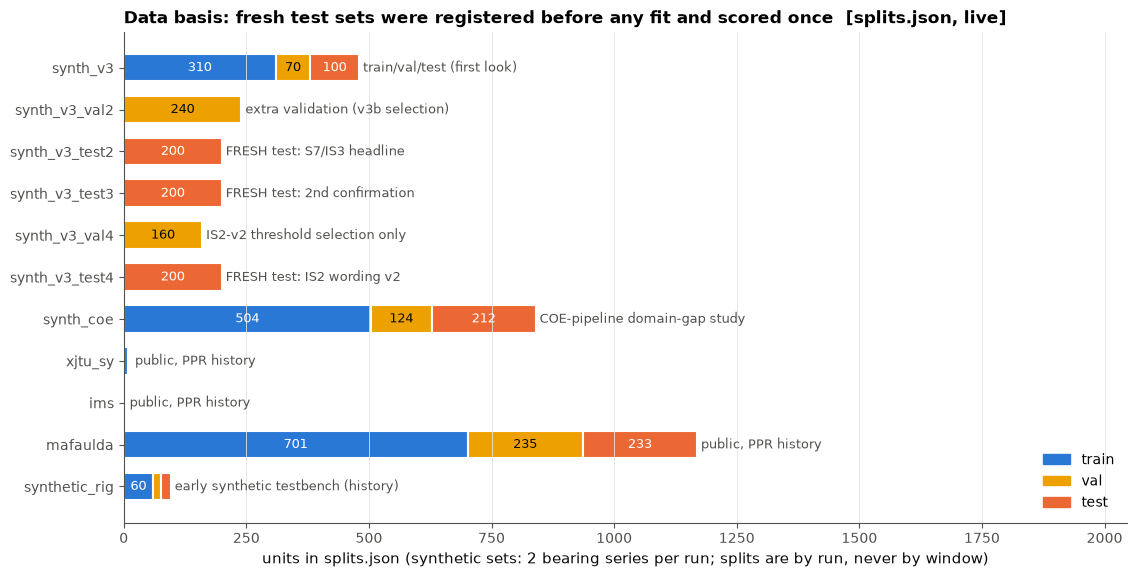

report,file (mtime),used for
UP2 spec check (newest),up2_spec_check_20261024T114947Z.json (file mtime 2026-10-24 14:49),"S7/IS3 stored context, spec-named models, S8 fallback"
UP2c spec check (newest),up2c_spec_check_20261024T175404Z.json (file mtime 2026-10-24 20:54),"2nd fresh set test3, IS2 v1 history (v3c)"
UP2d IS2 wording v2 (newest),up2d_is2_20261024T225605Z.json (file mtime 2026-10-25 01:56),IS2 v2 verdict (scored once on test4)
IS2 residual v1 (newest),up2_residual_20261024T173626Z.json (file mtime 2026-10-24 20:36),"IS2 v1 history (test2, tuned filter)"
COE verification,coe_verification.json (file mtime 2026-10-24 04:38),"COE stored context, IS1 COE leg"
IS1/S9 measurement (newest),integration_measurements_up2_v3b_20261024.md (file mtime 2026-10-24 16:32),S9/IS1 fallback if the live backend cannot run
PPR integration measurements,integration_measurements_20261005.md (file mtime 2026-10-24 04:07),history
PPR public-data result (v2),spec_check_20261005T012112Z_real_v2.json (file mtime 2026-10-24 04:07),"S7/IS3 on real bearings (history, FAIL)"


In [3]:
display(U.verdict("Data", True, "synthetic / simulated data, coach-approved substitute for rig data; fresh test sets scored once", "[SYNTHETIC] [SIMULATION]"))
try:
    SP = U.splits_frame()
    display(U.table(SP, caption="Registered data sets (live from AI-engine/splits.json; units = bearing series, splits are by run)"))
    chart(U.fig_data_basis, "data_basis.png", SP)
except Exception as e:
    display(U.missing(f"splits.json: {e}"))
spec_p, spec = U.stored_spec_check()
res_p, resid = U.residual_latest()
coe_p, coe_st = U.coe_stored()
int_p, integ = U.stored_integration()
ppr_int = U.EVIDENCE / "integration_measurements_20261005.md"
public_p = U.REPORTS / "spec_check_20261005T012112Z_real_v2.json"
up2c_p = U.newest(U.REPORTS, "up2c_spec_check_*.json")
up2d_p = U.newest(U.REPORTS, "up2d_is2_2*.json")
files = pd.DataFrame([{"report": k, "file (mtime)": U.stamp(p), "used for": u} for k, p, u in [
    ("UP2 spec check (newest)", spec_p, "S7/IS3 stored context, spec-named models, S8 fallback"),
    ("UP2c spec check (newest)", up2c_p, "2nd fresh set test3, IS2 v1 history (v3c)"),
    ("UP2d IS2 wording v2 (newest)", up2d_p, "IS2 v2 verdict (scored once on test4)"),
    ("IS2 residual v1 (newest)", res_p, "IS2 v1 history (test2, tuned filter)"),
    ("COE verification", coe_p, "COE stored context, IS1 COE leg"),
    ("IS1/S9 measurement (newest)", int_p, "S9/IS1 fallback if the live backend cannot run"),
    ("PPR integration measurements", ppr_int if ppr_int.exists() else None, "history"),
    ("PPR public-data result (v2)", public_p if public_p.exists() else None, "S7/IS3 on real bearings (history, FAIL)")]])
display(U.table(files, caption="Stored reports this notebook reads (names carry the UTC stamp)"))
if spec:
    display(U.details("Spec-check report metadata (commit, seed, command)", body_md="\n".join(f"- **{k}**: `{spec['meta'].get(k)}`" for k in ("git_commit", "git_dirty", "seed", "utc", "command"))))

## 2. C4: no cloud. The deployed engine runs with every network call blocked

C4 (COE-assigned in the sheet; **counted for ICS by team decision 2026-10-05**): *all real-time data acquisition and signal processing shall
execute on local hardware without cloud computation.* Inside a guard that makes every Python network primitive raise, the deployed v3b
engine classifies and predicts RUL over the demo payload stream.

check,status,detail
No-network guard active,PASS,socket.getaddrinfo('pypi.org') raised NetworkBlocked inside the guard
Deployed v3b engine produced outputs offline,PASS,120 x 152-byte payloads -> features -> classifier + RUL heads (ONNX)


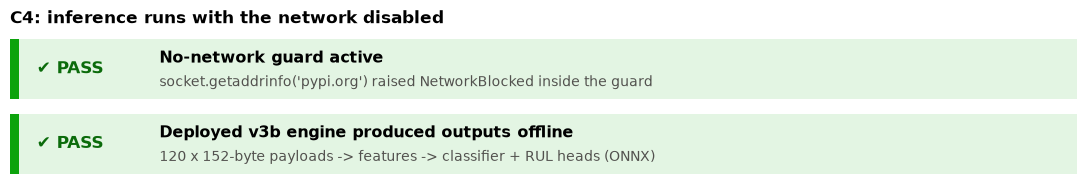

In [4]:
C4 = U.c4_no_network_live()
okC4 = C4["status"] == "ok" and C4["guard_blocks_dns"] and C4["ran"]
display(U.verdict("C4", okC4 if C4["status"] == "ok" else None, f"{C4.get('windows', '?')} windows classified + RUL with the network blocked (target: no cloud reliance)", "[MEASURED host]"))
if C4["status"] == "ok" and C4["guard_blocks_dns"] and C4["ran"]:
    U.record("C4", status="MET [MEASURED host]", value=f"{C4['windows']} windows classified + RUL with all network calls blocked (DNS lookup raised)", target="no cloud reliance", rank=7, firm=True, achievable=9,
             note="COE-assigned in the sheet; counted for ICS by team decision 2026-10-05. DAQ+DSP part = simulated COE pipeline running locally (S4-S6)", step="Repeat with the real node and a physically disconnected uplink",
             prov="[MEASURED host] (network-denied Python run)", source="live: up2_helpers.c4_no_network_live")
else:
    U.record("C4", status="NOT EVIDENCED (live check failed)", rank=0, note=str(C4))
if C4["status"] == "ok":
    checks = [("No-network guard active", C4["guard_blocks_dns"], "socket.getaddrinfo('pypi.org') raised NetworkBlocked inside the guard"),
              ("Deployed v3b engine produced outputs offline", C4["ran"], f"{C4['windows']} x 152-byte payloads -> features -> classifier + RUL heads (ONNX)")]
    display(U.table(pd.DataFrame([{"check": a, "status": "PASS" if b else "FAIL", "detail": c} for a, b, c in checks]), status_cols=["status"]))
    chart(U.fig_checks, "c4_checks.png", "C4: inference runs with the network disabled", checks)
else:
    display(U.missing(C4))
display(U.reading("No cloud service is on the path: the AI and the dashboard backend run on the local host. The node's acquisition/DSP part is the simulated COE pipeline running locally (section 5)."))

## 3. C5: dashboard on the local network only

The backend's LAN guard unit tests run live: `LanOnlyTests` (HTTP from a public address gets **403**, private and loopback pass) and
`UdpLanGuardTests` (UDP 5005 datagrams from public senders are dropped and counted).

test filter,passed,failed,total,seconds,status
LanOnlyTests | UdpLanGuardTests,19,0,19,3.80,PASS


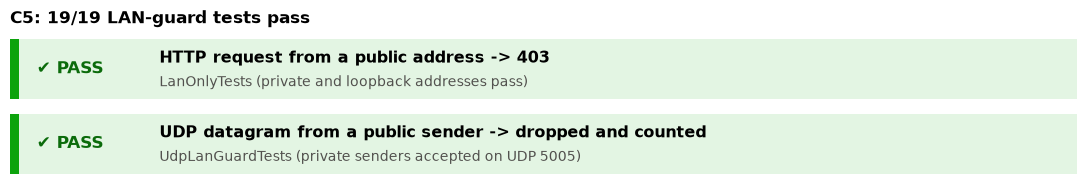

In [5]:
C5 = U.c5_live()
okC5 = C5["status"] == "ok" and C5["failed"] == 0 and C5["passed"] >= 19
display(U.verdict("C5", okC5 if C5["status"] == "ok" else None, f"{C5.get('passed', '?')}/{C5.get('total', '?')} LAN-guard tests pass live (target: LAN only)", "[MEASURED host]"))
if C5["status"] == "ok" and C5["failed"] == 0 and C5["passed"] >= 19:
    U.record("C5", status="MET [MEASURED host]", value=f"{C5['passed']}/{C5['total']} LanOnlyTests+UdpLanGuardTests pass (public HTTP clients 403, public UDP senders dropped)", target="LAN only", rank=9, firm=True, achievable=9,
             note="guard unit tests + Kestrel bind; the network-denied run covers the Python inference path, not the C# backend", step="Show a phone on the room Wi-Fi reaching the dashboard and a non-private client refused", prov="[MEASURED host]", source="live: dotnet test tests/DigitalTwin.Backend.Tests")
elif C5["status"] == "ok":
    U.record("C5", status="NOT MET (tests failing)", value=str(C5), rank=9)
else:
    U.record("C5", status="NOT EVIDENCED (dotnet test unavailable)", rank=0, note=str(C5), step="install .NET SDK / fix build")
if C5["status"] == "ok":
    display(U.table(pd.DataFrame([{"test filter": "LanOnlyTests | UdpLanGuardTests", "passed": C5["passed"], "failed": C5["failed"], "total": C5["total"],
                                   "seconds": C5.get("elapsed_s"), "status": "PASS" if okC5 else "FAIL"}]), status_cols=["status"]))
    ok = C5["failed"] == 0
    chart(U.fig_checks, "c5_checks.png", f"C5: {C5['passed']}/{C5['total']} LAN-guard tests pass", [
        ("HTTP request from a public address -> 403", ok, "LanOnlyTests (private and loopback addresses pass)"),
        ("UDP datagram from a public sender -> dropped and counted", ok, "UdpLanGuardTests (private senders accepted on UDP 5005)")])
else:
    display(U.missing(C5))
display(U.details("Scope and next step", body_md="- The network-denied run (C4) covers the Python inference path; C5 is the C# backend's guard plus the Kestrel bind.\n- Next step: a phone on the room Wi-Fi reaching the dashboard and a non-private client refused."))

## 4. S8: fault-classification inference < 200 ms per window (live)

The deployed v3b classifier (a gradient-boosted model in the TFT ONNX slot; **model change approved**) in a fresh ONNX Runtime session,
**1 intra-op thread, batch 1**, on real encoder windows of a `[SYNTHETIC]` run-to-failure bearing. Latency is `[MEASURED host]` (this PC; the
final server is a laptop or a Raspberry Pi 5).

what is timed,n,p50 ms,p95 ms,max ms,vs 200 ms,provenance
deployed classifier ONNX (S8 verdict),300.000,0.238,0.553,2.366,PASS,[MEASURED host] live
full engine step per bearing-window (features + classifier + RUL + post),216.000,3.716,5.200,6.940,PASS,[MEASURED host] live
"original TFT ONNX (spec-named, transparency)",-,-,1.541,-,PASS,[MEASURED host] stored report


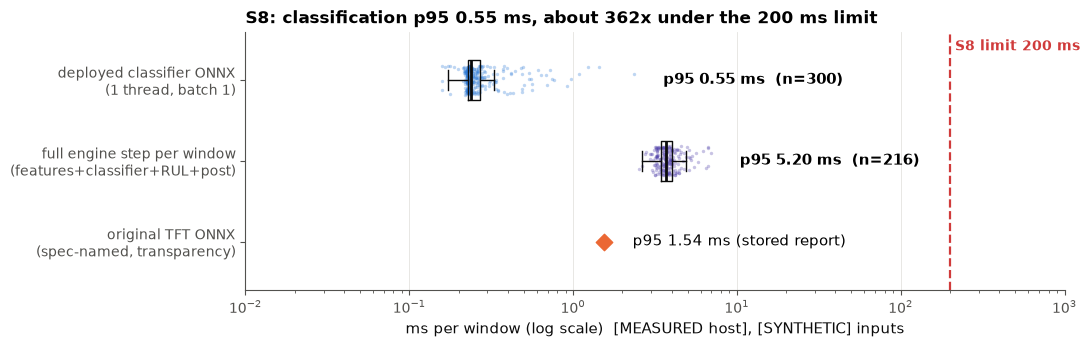

In [6]:
SN = U.spec_named_models(spec)
L8 = U.s8_latency_live()
if L8["status"] == "ok":
    c, e = L8["cls"], L8["engine_step"]
    display(U.verdict("S8", c["p95_ms"] < 200, f"classifier ONNX p95 {c['p95_ms']:.3f} ms vs target < 200 ms (n={c['n']})", "[MEASURED host] [SYNTHETIC]"))
    U.record("S8", status="MET [MEASURED host]" if c["p95_ms"] < 200 else "NOT MET", value=f"p95 {c['p95_ms']:.3f} ms (engine step p95 {e['p95_ms']:.2f} ms)", target="< 200 ms",
             note="the deployed classifier slot holds a gradient-boosted model in the TFT ONNX contract slot; the real TFT-slot ONNX is about 1.5-12 ms depending on host load/threads (PPR 11.1 ms)", rank=9, firm=True,
             deployed="MODEL CHANGE APPROVED: gradient-boosted classifier in the TFT ONNX slot", specnamed=(f"original TFT ONNX p95 {SN['tft_p95']:.2f} ms (also passes)" if SN else "missing"),
             achievable=9, step="Re-measure on the final server (laptop or Raspberry Pi 5)", prov="[MEASURED host] latency, [SYNTHETIC] inputs", source="live: up2_helpers.s8_latency_live; " + U.stamp(spec_p))
    rows = [{"what is timed": "deployed classifier ONNX (S8 verdict)", "n": c["n"], "p50 ms": c["p50_ms"], "p95 ms": c["p95_ms"], "max ms": c["max_ms"], "vs 200 ms": "PASS" if c["max_ms"] < 200 else "FAIL", "provenance": "[MEASURED host] live"},
            {"what is timed": "full engine step per bearing-window (features + classifier + RUL + post)", "n": e["n"], "p50 ms": e["p50_ms"], "p95 ms": e["p95_ms"], "max ms": e["max_ms"], "vs 200 ms": "PASS" if e["max_ms"] < 200 else "FAIL", "provenance": "[MEASURED host] live"}]
    if SN:
        rows.append({"what is timed": "original TFT ONNX (spec-named, transparency)", "n": None, "p50 ms": None, "p95 ms": SN["tft_p95"], "max ms": None, "vs 200 ms": "PASS" if SN["tft_p95"] < 200 else "FAIL", "provenance": "[MEASURED host] stored report"})
    display(U.table(pd.DataFrame(rows), status_cols=["vs 200 ms"], precision=3))
    chart(U.fig_s8, "s8_latency.png", L8["cls_ms"], L8["step_ms"], SN.get("tft_p95") if SN else None)
    display(U.reading(f"**S8 latency statement (this live cell is canonical; quote the range, not one fixed number):** classifier ONNX p95 is sub-millisecond, 0.04-0.4 ms depending on host load; this run {c['p95_ms']:.3f} ms. The TFT-slot ONNX is about 1.5-12 ms depending on host load/threads. All are far under the 200 ms limit."))
else:
    display(U.verdict("S8", None, "live latency run failed; stored value used if present", "[MEASURED host]")); display(U.missing(L8))
    lat = ((spec or {}).get("latency") or {}).get("v3b_cls_onnx")
    if lat: U.record("S8", status="MET [MEASURED host]" if lat["p95_ms"] < 200 else "NOT MET", value=f"p95 {lat['p95_ms']:.3f} ms (STORED)", target="< 200 ms", rank=6, achievable=9, step="fix the live cell", prov="[MEASURED host] stored", source=U.stamp(spec_p))

## 5. COE edge pipeline: S4 (sample rate), S5 (window to payload), S6 (fixed AI input), live

`aiengine.coe` is the COE pipeline as code (the code that becomes the STM32 firmware): `SampleSource` -> 30 kS/s DSP -> 152-byte payload.
The checks below run live (`coe.verify --quick` style: 4 s of simulated rig for S4, 40 windows per rpm for S5, 28 speeds for S6).

item,measured,target,status,rank,provenance
S4 sample rate,"30 kS/s/ch, margin 20.0 %, slack 16.3 us; sim 3.994 s, 4 ch, gap-free True",>= 25 kS/s/ch x 4,PASS,3,[CALCULATED] + [SIMULATION]
S5 window -> payload,"host worst 7.76 ms; STM32 pessimistic (10 cyc/flop, 480 MHz assumed) 28.4 ms",<= 333 ms,PASS,3,[MEASURED host] + [CALCULATED]
S6 fixed AI input,"28 speeds: identical shapes True, payload bytes [152], finite True","fixed dim + order, 1000-3600 rpm",PASS,6,[SIMULATION]


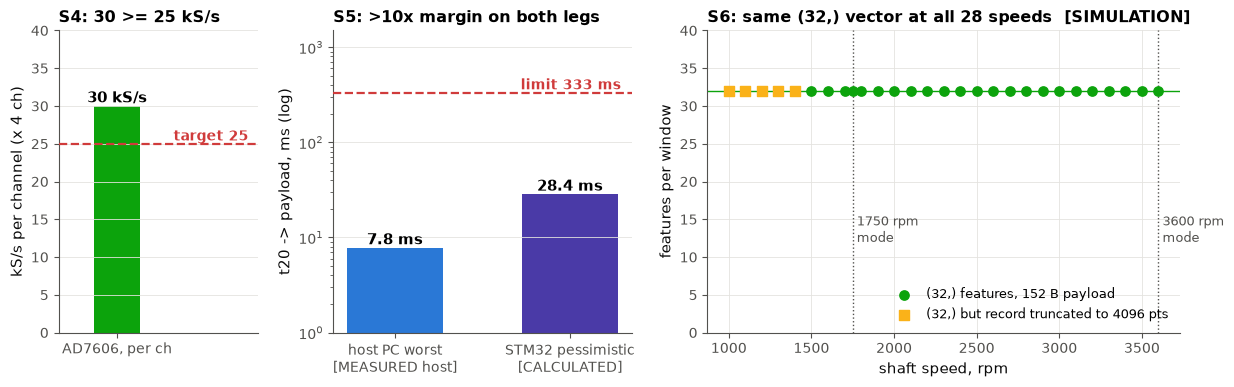

In [7]:
CO = U.coe_live(quick=True)
if CO["status"] == "ok":
    c1, c2, c3 = CO["COE1"], CO["COE2"], CO["COE3"]
    host = c2["host"]["by_rpm"] if "host" in c2 and "by_rpm" in c2.get("host", {}) else c2["by_rpm"]
    worst = max(v["t20_to_payload_ms"]["max"] for v in host.values())
    stm = c2["stm32_estimate"]["by_rpm"]; stm_ms = max(v["pessimistic_10cyc_per_flop"]["plus_wait_for_block_end_ms"] for v in stm.values())
    ok4 = c1["calculated"]["per_channel_rate_ksps"] >= 25 and c1["simulation"]["dma_sequence_gap_free"] and c1["simulation"]["channels_with_signal"] == 4
    ok5 = worst <= 333 and stm_ms <= 333; ok6 = c3["identical_shapes"] and c3["all_finite"]
    n_tr = sum(1 for r in c3["rows"] if r["envelope_record_truncated_to_4096"])
    display(U.verdict("S4", ok4, f"{c1['calculated']['per_channel_rate_ksps']:.0f} kS/s per channel x 4 ch, gap-free DMA in simulation (target >= 25)", "[CALCULATED] [SIMULATION]"))
    display(U.verdict("S5", ok5, f"host worst {worst:.2f} ms; STM32 pessimistic {stm_ms:.1f} ms (target <= 333 ms)", "[MEASURED host] [CALCULATED]"))
    display(U.verdict("S6", ok6, f"(32,) features / 152 B at all {c3['n_speeds']} speeds, 1000-3600 rpm (target: fixed dimension and ordering)", "[SIMULATION]"))
    U.record("S4", status="MET [SIMULATION+CALCULATED]" if ok4 else "NOT MET", value=f"{c1['calculated']['per_channel_rate_ksps']:.0f} kS/s/ch x 4 ch, gap-free sim, {c1['calculated']['slack_before_next_convst_us']} us slack", target=">= 25 kS/s/ch",
             note="ADC timing from datasheet figures in the COE doc; the simulated source emits whatever rate it is told, so the gap-free check cannot fail (Rank 3: calculation + non-falsifiable simulation)", rank=3, firm=False, achievable=9, step="AD7606 on the bench: capture 4 ch at 30 kS/s and show gap-free DMA",
             prov="[CALCULATED] + [SIMULATION]", source="live: aiengine.coe.verify.coe1; " + U.stamp(coe_p))
    U.record("S5", status="MET [MEASURED host + CALCULATED]" if ok5 else "NOT MET", value=f"host worst {worst:.2f} ms; STM32 pessimistic calc {stm_ms:.1f} ms", target="<= 333 ms",
             note="host time is a Python/NumPy run on this PC, NOT STM32 time; the STM32 leg is a calculation with an assumed core/clock (Rank 3)", rank=3, firm=False, achievable=9, step="Run the C port on the STM32H755 and time t20 -> payload with a GPIO/DWT counter",
             prov="[MEASURED host] + [CALCULATED]", source="live: aiengine.coe.verify.coe2; " + U.stamp(coe_p))
    U.record("S6", status="MET [SIMULATION]" if ok6 else "NOT MET", value=f"{c3['n_speeds']} speeds 1000-3600 rpm -> all (32,) features / 152 B, finite", target="fixed dimension and ordering",
             note=f"DISCLOSURE: below ~1465 rpm the 20-rev envelope record exceeds the 4096-pt FFT and is truncated ({n_tr} of {c3['n_speeds']} swept speeds); the supported modes 1750/3600 rpm are not truncated. COE open question.", rank=6, firm=True, achievable=9, step="Same pipeline on real accelerometer data at several VFD speeds",
             prov="[SIMULATION]", source="live: aiengine.coe.verify.coe3; " + U.stamp(coe_p))
    display(U.table(pd.DataFrame([
        {"item": "S4 sample rate", "measured": f"{c1['calculated']['per_channel_rate_ksps']:.0f} kS/s/ch, margin {c1['calculated']['margin_pct']} %, slack {c1['calculated']['slack_before_next_convst_us']} us; sim {c1['simulation']['simulated_seconds']} s, {c1['simulation']['channels_with_signal']} ch, gap-free {c1['simulation']['dma_sequence_gap_free']}", "target": ">= 25 kS/s/ch x 4", "status": "PASS" if ok4 else "FAIL", "rank": 3, "provenance": "[CALCULATED] + [SIMULATION]"},
        {"item": "S5 window -> payload", "measured": f"host worst {worst:.2f} ms; STM32 pessimistic (10 cyc/flop, 480 MHz assumed) {stm_ms:.1f} ms", "target": "<= 333 ms", "status": "PASS" if ok5 else "FAIL", "rank": 3, "provenance": "[MEASURED host] + [CALCULATED]"},
        {"item": "S6 fixed AI input", "measured": f"{c3['n_speeds']} speeds: identical shapes {c3['identical_shapes']}, payload bytes {c3['payload_bytes_set']}, finite {c3['all_finite']}", "target": "fixed dim + order, 1000-3600 rpm", "status": "PASS" if ok6 else "FAIL", "rank": 6, "provenance": "[SIMULATION]"}]),
        status_cols=["status"], caption=f"COE checks, live run {CO['seconds']} s"))
    chart(U.fig_coe, "coe_s4_s5_s6.png", c1, worst, stm_ms, c3)
    display(U.details("Disclosures (S4, S5, S6)", body_md=f"- **S4** is Rank 3: ADC timing from datasheet figures in the COE doc; the simulated source emits whatever rate it is told, so the gap-free check cannot fail.\n- **S5** host time is a Python/NumPy run on this PC, NOT STM32 time; the STM32 leg is a calculation with an assumed core/clock (Rank 3). Next: run the C port on the STM32H755 with a GPIO/DWT counter.\n- **S6**: below ~1465 rpm the 20-rev envelope record exceeds the 4096-pt FFT and is truncated ({n_tr} of {c3['n_speeds']} swept speeds, amber squares); the supported modes 1750/3600 rpm are not truncated. COE open question."))
else:
    display(U.missing(CO))
    for i in ("S4","S5","S6"): U.record(i, status="NOT EVIDENCED (live COE check failed)", rank=0, note=str(CO))

## 6. Raw vibration to prediction, end to end (centrepiece)

<div style="display:flex;flex-wrap:wrap;align-items:center;gap:6px;font:13px system-ui,Segoe UI,Arial;margin:8px 0">
<span style="border:2px solid #4a3aa7;border-radius:6px;padding:6px 10px;background:#f1effa"><b>SampleSource</b><br>4 ch IEPE, 30 kS/s<br><small>[SIMULATION] today, AD7606 on hardware day</small></span> &rarr;
<span style="border:2px solid #4a3aa7;border-radius:6px;padding:6px 10px;background:#f1effa"><b>COE pipeline</b><br>band-pass, envelope, 4096-pt FFT<br><small>S4 S5 S6</small></span> &rarr;
<span style="border:2px solid #4a3aa7;border-radius:6px;padding:6px 10px;background:#f1effa"><b>152-byte payload</b><br>32 features + rpm + t20<br><small>UDP 5005 (Wi-Fi)</small></span> &rarr;
<span style="border:2px solid #2a78d6;border-radius:6px;padding:6px 10px;background:#eef4fc"><b>Backend engine</b><br>classifier + RUL heads (ONNX)<br><small>S7 S8 IS3</small></span> &rarr;
<span style="border:2px solid #2a78d6;border-radius:6px;padding:6px 10px;background:#eef4fc"><b>Dashboard</b><br>SignalR, LAN only<br><small>C5 S9 IS1</small></span>
</div>

**Step 1, raw to features**: the real `aiengine.coe` code turns simulated raw samples into the envelope spectrum and the 8 features per channel.
**Step 2, stream through the deployed engine**: the `[SYNTHETIC]` demo stream (the one the dashboard replays) through the v3b engine.

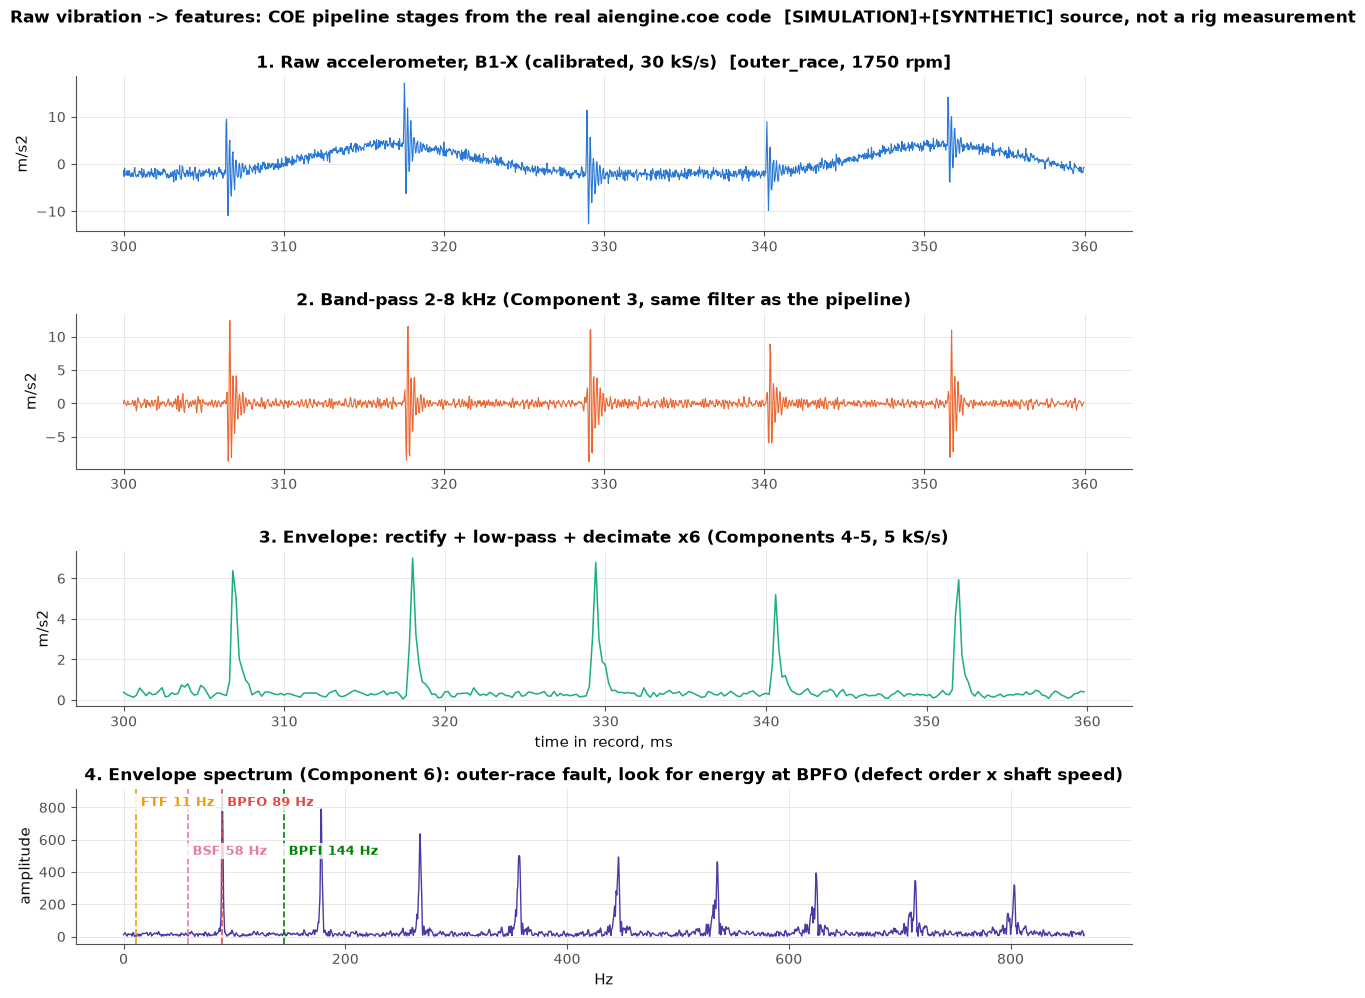

In [8]:
try:
    fig = U.coe_stage_figure(None); p = show(fig, "coe_pipeline_stages.png")
    display(U.reading("Each stage is drawn from the real pipeline filters: the band-pass removes the shaft-rate content, the envelope exposes the impact rate, and the envelope spectrum shows energy at the bearing-defect orders. These per-channel band energies are 4 of the 8 features that go into the 152-byte payload. `[SIMULATION]` + `[SYNTHETIC]` source, not a rig measurement."))
except Exception as e:
    display(U.missing(f"stage figure: {type(e).__name__}: {e}"))

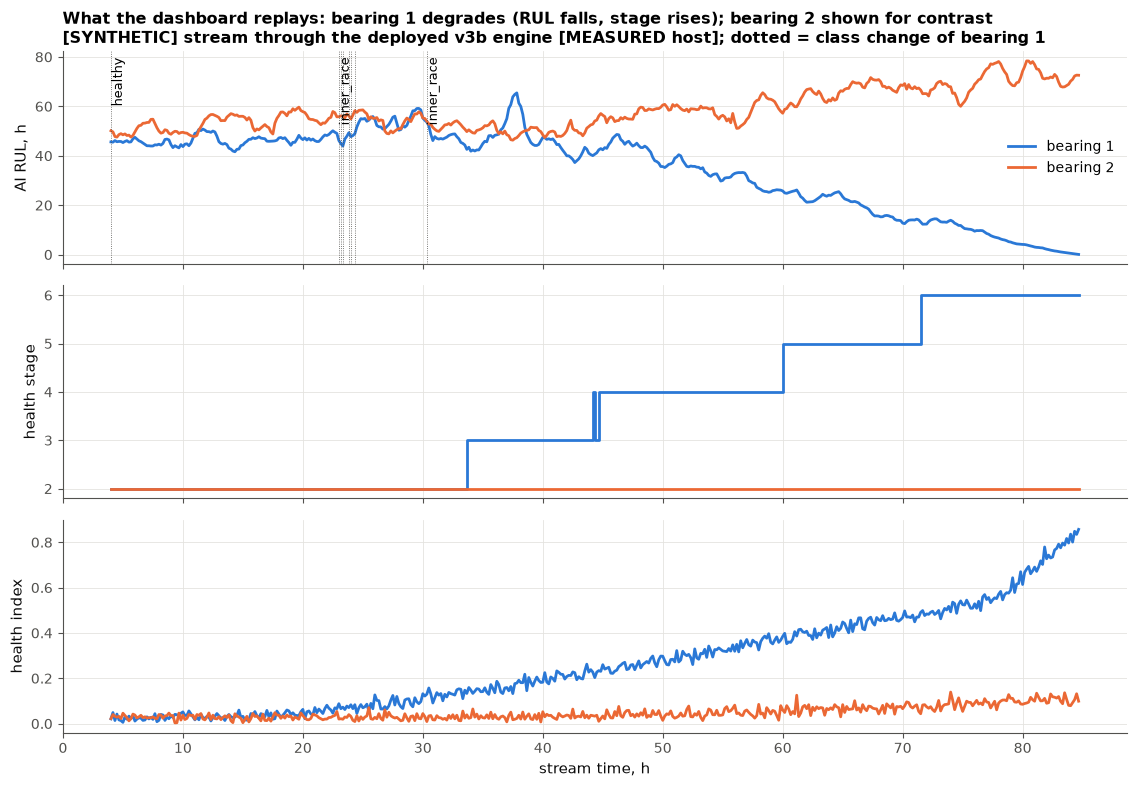

bearing,scored windows,classes called,stage range,"RUL first -> last, h",engine latency p95 ms
1,485,"inner_race 333, healthy 152",2 to 6,45.6 -> 0.1,4.77
2,485,"healthy 484, inner_race 1",2 to 2,50.1 -> 72.6,5.06


In [9]:
try:
    TL, fg, meta = U.demo_timeline(None); show(fg, "up2_demo_timeline.png")
    rows = []
    for b in sorted(TL.bearing.unique()):
        d = TL[TL.bearing == b]
        rows.append({"bearing": int(b), "scored windows": len(d), "classes called": ", ".join(f"{k} {v}" for k, v in d.cls.value_counts().items()),
                     "stage range": f"{int(d.stage.min())} to {int(d.stage.max())}", "RUL first -> last, h": f"{d.rul_h.iloc[0]:.1f} -> {d.rul_h.iloc[-1]:.1f}",
                     "engine latency p95 ms": round(float(d.lat_ms.quantile(.95)), 2)})
    display(U.table(pd.DataFrame(rows), caption="Demo stream through the deployed v3b engine  [SYNTHETIC] stream, [MEASURED host] engine"))
except Exception as e:
    display(U.missing(f"timeline: {type(e).__name__}: {e}"))

## 7. S7: RUL MAPE <= 15 % on the held-out degradation window

The **fresh** `synth_v3_test2` runs (100 runs, new seed, registered in `splits.json` before any v3b fit, predicted **once**) are regenerated
deterministically (table hash shown) and the saved per-window predictions are re-scored here with the pre-registered metric of
`aiengine/up2_metrics.py`: MAPE in absolute hours over **[detected onset, T_fail - 10 % of the span]**, per bearing, then the mean over bearings.
No retraining. The spec names N-HiTS; the deployed RUL head is a **LightGBM direct-RUL head in the N-HiTS ONNX slot (model change approved)**.

reading,value %,target %,status,note
"S7 spec metric (pre-registered, detected onset)",12.64,15.00,PASS,-
stricter variant (true onset),14.72,15.00,PASS,-
"percent-of-life error (alternative, points)",5.81,-,-,-
per-bearing MAPE: median / p90 / max,-,-,-,11.2 / 19.5 / 26.4 %; share <= 15 %: 75 %


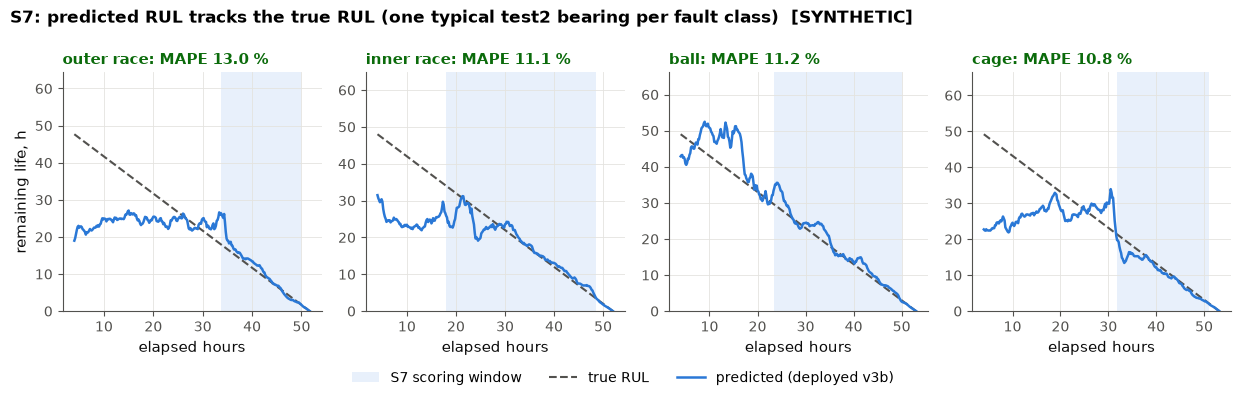

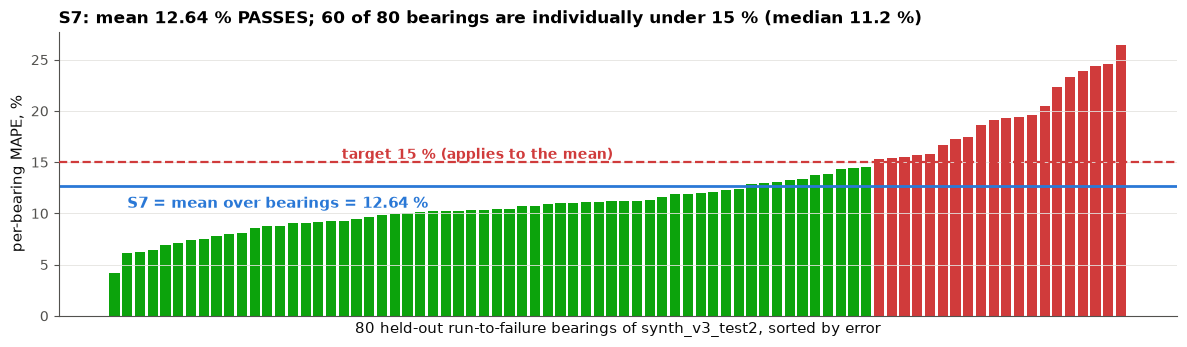

In [10]:
R = U.rescore_v3b()
if R["status"] != "ok":
    display(U.verdict("S7", None, "live re-score unavailable", "[SYNTHETIC]")); display(U.missing(R))
    U.record("S7", status="NOT EVIDENCED (re-score failed)", rank=0, note=str(R)); U.record("IS3", status="NOT EVIDENCED (re-score failed)", rank=0, note=str(R))
else:
    display(U.verdict("S7", R["S7"] <= 15, f"RUL MAPE {R['S7']:.2f} % vs target <= 15 % (n={R['n_rtf']} held-out bearings, fresh test2)", "[SYNTHETIC]"))
    s7ok = R["S7"] <= 15
    ist = R["F1"] >= .85 and R["stage_max"] <= 1 and R["caught"] == R["rtf"]
    U.record("S7", status="MET [SYNTHETIC]" if s7ok else "NOT MET [SYNTHETIC]", value=f"{R['S7']:.2f} % MAPE (strict-onset variant {R['S7_strict']:.2f} %)", target="<= 15 %",
             note="stored fresh-test2 predictions re-scored (Rank 6) + live ONNX subset run in 1c (Rank 9 if it passes). Pre-registered window (starts at DETECTED onset, drops the last 10 % of the span), synthetic data. Strict true-onset variant 14.72 % (passes by 0.28 pts) and 17.44 % on the old test (FAIL). On PUBLIC data (XJTU/IMS) the same spec FAILS: 281.8 %", rank=6, firm=True, deployed="MODEL CHANGE APPROVED: LightGBM direct-RUL head + causal post-process in the N-HiTS ONNX slot",
             specnamed=(f"original N-HiTS, for transparency: S7 {SN['S7']:.1f} % (worse)" if SN else "missing"), achievable="9 (form); evidence class stays synthetic until rig data",
             step="Rig run-to-failure or seeded-fault data to move from synthetic to measured", prov="[SYNTHETIC] synth_v3_test2 (+ [MEASURED on XJTU-SY/IMS] FAIL carried)",
             source=f"{R['index']} re-scored live; {U.stamp(spec_p)}")
    U.record("IS3", status="MET [SYNTHETIC]" if ist else "NOT MET [SYNTHETIC]", value=f"F1 {R['F1']:.3f}; stage max {R['stage_max']}; caught {R['caught']}/{R['rtf']}", target="F1>=0.85; stage err<=1; caught by stage 3",
             note="PUBLIC DATA: F1 0.581, stage max 4, 1/4 caught (FAIL, PPR v2)", rank=6, firm=True, deployed="MODEL CHANGE APPROVED: XGBoost classifier + LightGBM stage head + post-process in the TFT ONNX slot",
             specnamed=(f"original TFT, for transparency: F1 {SN['F1']:.3f}, stage max error {SN['stage_max']} (worse), caught {SN['caught']}" if SN else "missing"), achievable="9 (form); evidence class stays synthetic until rig data", step="Same as S7: needs rig fault data",
             prov="[SYNTHETIC] synth_v3_test2 (+ [MEASURED on public data] FAIL carried)", source=f"{R['index']} re-scored live; {U.stamp(spec_p)}")
    try:
        stored = json.loads(spec_p.read_text())["test"]["v3b:test2"]
        agree = abs(stored["rul"]["S7_mape_pct"] - R["S7"]) + abs(stored["classification"]["macro_f1"] - R["F1"])
    except Exception as e:
        agree = None
    rs = R["score"]["rul"]; pbs = rs.get("per_bearing_summary", {})
    display(U.table(pd.DataFrame([
        {"reading": "S7 spec metric (pre-registered, detected onset)", "value %": R["S7"], "target %": 15.0, "status": "PASS" if R["S7"] <= 15 else "FAIL"},
        {"reading": "stricter variant (true onset)", "value %": R["S7_strict"], "target %": 15.0, "status": "PASS" if R["S7_strict"] <= 15 else "FAIL"},
        {"reading": "percent-of-life error (alternative, points)", "value %": R["S7_pol"], "target %": None, "status": "-"},
        {"reading": "per-bearing MAPE: median / p90 / max", "value %": None, "target %": None, "status": "-", "note": f"{pbs.get('median', float('nan')):.1f} / {pbs.get('p90', float('nan')):.1f} / {pbs.get('max', float('nan')):.1f} %; share <= 15 %: {100*pbs.get('frac_le_15', float('nan')):.0f} %"}]),
        status_cols=["status"], caption=f"S7 on fresh test2: {R['n_rtf']} bearings, {rs['n_windows_s7']} scored windows, table hash {R['table_hash']}, re-scored in {R['seconds']} s"))
    display(HTML(U.tag("[SYNTHETIC]") + f' <span style="font-size:12px;color:#52514e">predictions {R["index"]}; agreement with stored report {spec_p.name}: |dS7|+|dF1| = {agree:.2e}</span>' if agree is not None else ""))
    chart(U.fig_s7_curves, "s7_rul_curves.png", R["rr"], rs["per_bearing_mape_pct"])
    chart(U.fig_s7_bars, "s7_per_bearing_mape.png", rs["per_bearing_mape_pct"], R["S7"])

### 7b. The values behind S7: a second fresh set and a live run of the deployed ONNX heads

- **Live ONNX run (Rank 9 for the subset).** The re-score above uses *stored* predictions (Rank 6). The cell below **runs the deployed v3b
  engine** (`HybridEngine`: features, ONNX classifier and RUL heads, post-process) window by window on regenerated `synth_v3_test2` runs and
  recomputes every metric **from the model outputs**. Subset: every 5th run-to-failure bearing + 8 healthy-companion bearings.
- **Second fresh set `synth_v3_test3`** (100 runs, new seed), registered before the v3c fit (commit 3904a0c) and scored once (b71f165).
  How many times each set was seen: old `synth_v3` test twice (v3, then v3b); `test2`: predicted once, then only re-scored read-only; `test3`: once.

run,bearings,S7 %,S7 vs 15 %,IS3 macro-F1,stage max,caught,rank,provenance
"fresh test2, stored predictions re-scored (headline)",80,12.64,PASS,0.9587,1,80/80,6,[SYNTHETIC]
"LIVE deployed ONNX engine, subset (16 RTF + 8 healthy, 9022 windows, 79.7 s)",16,13.17,PASS,0.9635,1,16/16,9,[SYNTHETIC] [MEASURED host]
"2nd fresh set test3, scored once (stored, commit b71f165, 77198 windows)",80,10.75,PASS,0.9615,1,80/80,6,[SYNTHETIC]


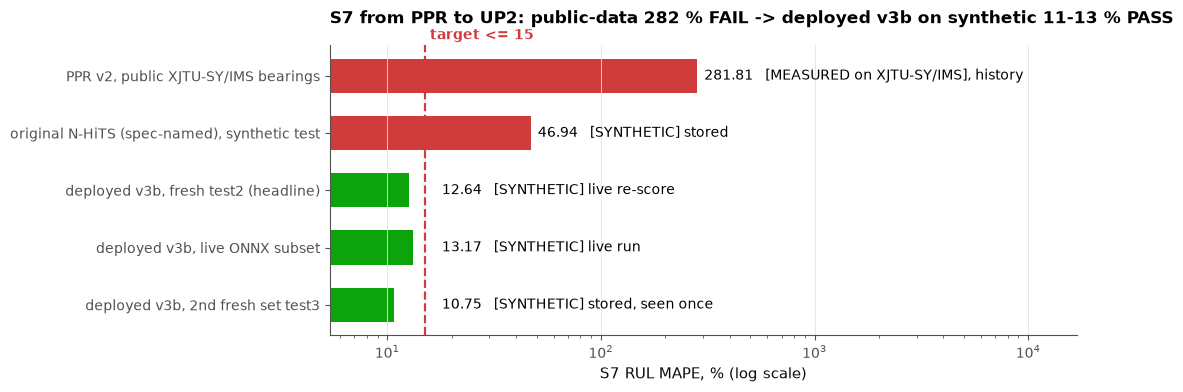

In [11]:
LE = U.live_engine_run(step=5, n_healthy=8)
UC = U.load_json(up2c_p)
rows = []
if R["status"] == "ok":
    rows.append({"run": "fresh test2, stored predictions re-scored (headline)", "bearings": R["n_rtf"], "S7 %": R["S7"], "IS3 macro-F1": R["F1"], "stage max": R["stage_max"], "caught": f"{R['caught']}/{R['rtf']}", "rank": 6, "provenance": "[SYNTHETIC]"})
if LE["status"] == "ok":
    okS7 = LE["rul"]["S7_mape_pct"] <= 15
    okI3 = LE["cls"]["macro_f1"] >= .85 and LE["stage"]["max_abs_error"] <= 1 and LE["caught"]["caught_by_stage3"] == LE["caught"]["rtf_bearings"]
    sub = f"live ONNX subset ({LE['n_rtf']} bearings): "
    if "S7" in U.REG and U.REG["S7"].get("status", "").startswith("MET") and okS7:
        U.REG["S7"].update(rank=9, note=U.REG["S7"]["note"] + " | " + sub + f"MAPE {LE['rul']['S7_mape_pct']:.2f} % recomputed from live model outputs (Rank 9 for the subset; the 80-bearing figure is Rank 6).")
    if "IS3" in U.REG and U.REG["IS3"].get("status", "").startswith("MET") and okI3:
        U.REG["IS3"].update(rank=9, note=U.REG["IS3"]["note"] + " | " + sub + f"F1 {LE['cls']['macro_f1']:.3f}, stage max {LE['stage']['max_abs_error']}, caught {LE['caught']['caught_by_stage3']}/{LE['caught']['rtf_bearings']} from live model outputs (Rank 9 for the subset).")
    rows.append({"run": f"LIVE deployed ONNX engine, subset ({LE['n_rtf']} RTF + {LE['n_healthy']} healthy, {LE['windows']} windows, {LE['seconds']} s)", "bearings": LE["rul"]["n_bearings"], "S7 %": LE["rul"]["S7_mape_pct"],
                 "IS3 macro-F1": LE["cls"]["macro_f1"], "stage max": LE["stage"]["max_abs_error"], "caught": f"{LE['caught']['caught_by_stage3']}/{LE['caught']['rtf_bearings']}", "rank": 9 if (okS7 and okI3) else 6, "provenance": "[SYNTHETIC] [MEASURED host]"})
    if not (okS7 and okI3): display(HTML(U.pill("PARTIAL", "the live subset does NOT pass every target; S7/IS3 stay at Rank 6")))
else:
    display(U.missing(LE))
if UC:
    b = UC["models"]["v3b"]
    ok3 = b["rul"]["S7_mape_pct"] <= 15 and b["classification"]["macro_f1"] >= .85 and b["stage"]["max_abs_error"] <= 1 and b["caught"]["caught_by_stage3"] == b["caught"]["rtf_bearings"]
    extra = f" | 2nd fresh set synth_v3_test3 (stored report {up2c_p.name}, seen once): S7 {b['rul']['S7_mape_pct']:.2f} %, F1 {b['classification']['macro_f1']:.3f}, stage max {b['stage']['max_abs_error']}, caught {b['caught']['caught_by_stage3']}/{b['caught']['rtf_bearings']} ({'confirms' if ok3 else 'DOES NOT confirm'})"
    for k in ("S7", "IS3"):
        if k in U.REG: U.REG[k]["note"] = U.REG[k].get("note", "") + extra
    rows.append({"run": f"2nd fresh set test3, scored once (stored, commit {UC['meta']['git_commit']}, {UC['data']['windows']} windows)", "bearings": b["rul"]["n_bearings"], "S7 %": b["rul"]["S7_mape_pct"], "IS3 macro-F1": b["classification"]["macro_f1"],
                 "stage max": b["stage"]["max_abs_error"], "caught": f"{b['caught']['caught_by_stage3']}/{b['caught']['rtf_bearings']}", "rank": 6, "provenance": "[SYNTHETIC]"})
else:
    display(U.missing("reports/up2c_spec_check_*.json"))
if rows:
    T7 = pd.DataFrame(rows); T7["S7 vs 15 %"] = ["PASS" if v <= 15 else "FAIL" for v in T7["S7 %"]]
    display(U.table(T7[["run", "bearings", "S7 %", "S7 vs 15 %", "IS3 macro-F1", "stage max", "caught", "rank", "provenance"]], status_cols=["S7 vs 15 %"], fmt={"IS3 macro-F1": "{:.4f}", "S7 %": "{:.2f}"}, caption="Same deployed model, three independent looks"))
if LE["status"] == "ok":
    extra_txt = f"; agreement with the stored predictions on the same windows: class {LE['agree_class_frac']:.4f}, RUL median relative difference {LE['agree_rul_median_abs_rel_diff_pct']:.3f} %" if "agree_class_frac" in LE else ""
    display(HTML(f'<div style="font-size:12px;color:#52514e">live engine latency per bearing-window p50 {LE["lat_p50"]:.2f}, p95 {LE["lat_p95"]:.2f}, max {LE["lat_max"]:.2f} ms {U.tag("[MEASURED host]")}{extra_txt}</div>'))
cmp = [("PPR v2, public XJTU-SY/IMS bearings", 281.8, False, "[MEASURED on XJTU-SY/IMS], history")]
if SN: cmp.append(("original N-HiTS (spec-named), synthetic test", SN["S7"], SN["S7"] <= 15, "[SYNTHETIC] stored"))
if R["status"] == "ok": cmp.append(("deployed v3b, fresh test2 (headline)", R["S7"], R["S7"] <= 15, "[SYNTHETIC] live re-score"))
if LE["status"] == "ok": cmp.append(("deployed v3b, live ONNX subset", LE["rul"]["S7_mape_pct"], LE["rul"]["S7_mape_pct"] <= 15, "[SYNTHETIC] live run"))
if UC: cmp.append(("deployed v3b, 2nd fresh set test3", UC["models"]["v3b"]["rul"]["S7_mape_pct"], UC["models"]["v3b"]["rul"]["S7_mape_pct"] <= 15, "[SYNTHETIC] stored, seen once"))
try:
    pj = U.load_json(public_p if public_p.exists() else None); v = (pj.get("verdicts") or pj.get("metrics", {}).get("verdicts")) if pj else None
    s7pub = next(x["measured"] for x in v if x["spec"] == "S7") if v else None
    if s7pub is not None: cmp[0] = ("PPR v2, public XJTU-SY/IMS bearings", float(s7pub), float(s7pub) <= 15, "[MEASURED on XJTU-SY/IMS], history")
except Exception:
    pass
chart(U.fig_compare, "s7_ppr_vs_up2.png", cmp, 15, "S7 RUL MAPE, % (log scale)", "S7 from PPR to UP2: public-data 282 % FAIL -> deployed v3b on synthetic 11-13 % PASS", log=True)
display(U.reading("S7 passes on three independent synthetic looks (12.64 % headline). On real public bearings the same spec still fails (PPR history): the evidence class stays **synthetic** until rig run-to-failure data exists."))

In [12]:
if R["status"] == "ok":
    disc = (f"- **S7 definition**: pre-registered window = [detected onset, T_fail - 10 % of the span], bearing-averaged. The STRICT true-onset variant is {R['S7_strict']:.2f} % on test2 (passes by {15-R['S7_strict']:.2f} pts) and 17.44 % on the older test set (FAIL).\n"
            + (f"- **Healthy-companion bearings** ({R['healthy_windows']} scored windows): predicted stage 2 in {100*R['healthy_stage2_share']:.1f} % of windows while the true stage is 1 in {100*R['healthy_true_stage1_share']:.1f} %. IS3b scores run-to-failure bearings only, so this is invisible in the metric.\n" if R.get("healthy_stage2_share") is not None else "")
            + "- **Domain gap**: the classifier/RUL heads were trained on payload-level synthetic features, not COE-pipeline output (bearing 2 is misclassified in the COE simulator demo; see Additional items, COE adaptation).\n"
            + (f"- **Spec-named models** on the same synthetic test data (stored report): N-HiTS S7 {SN['S7']:.1f} %, TFT macro-F1 {SN['F1']:.3f}, TFT stage max error {SN['stage_max']}, caught {SN['caught']}, TFT ONNX p95 {SN['tft_p95']:.2f} ms. Model change to gradient-boosted heads approved for performance.\n" if SN else ""))
    display(U.details("Disclosures (ML, S7 and IS3): read before quoting", body_md=disc))
pj = U.load_json(public_p if public_p.exists() else None)
if pj:
    v = pj.get("verdicts") or pj.get("metrics", {}).get("verdicts")
    if v:
        dfp = pd.DataFrame(v)[[c for c in ("spec", "requirement", "target", "measured", "status") if c in pd.DataFrame(v).columns]]
        display(U.details("PPR v2 on PUBLIC data (XJTU-SY / IMS / MaFaulDa): the real-bearing numbers, history, still FAIL S7/IS3",
                          body_html=U.table(dfp, status_cols=["status"]).to_html() + "<div>" + U.tag("[MEASURED on XJTU-SY / IMS / MaFaulDa]") + " " + U._esc(U.stamp(public_p)) + "</div>"))
else:
    display(U.missing(public_p))

spec,requirement,target,measured,status
S7,RUL MAPE on held-out degradation window (N-HiTS),15.00,281.81,FAIL
S8,"TFT classification latency per window, p95 single-window",200.00,11.14,PASS
IS3a,macro-F1 over the testable classes (train AND test support; primary),0.85,0.58,FAIL
IS3a-5,macro-F1 over all 5 classes (a class with no output channel scores F1 0),0.85,0.58,FAIL
IS3b,"stage error <= 1, literal reading: MAX abs stage error over test windows",1.00,4.00,FAIL
IS3c,run-to-failure faults caught (3 consecutive correct) by stage 3,1.00,0.25,FAIL
IS1 (ICS leg),"features + TFT + N-HiTS + RUL per window, p95",500.00,14.42,PASS


## 8. IS3: macro-F1 >= 0.85 over {healthy, outer race, inner race, ball, cage}; stage error <= 1; any injected fault caught by stage 3

Same fresh `synth_v3_test2` re-score as S7 (registry entry recorded in section 7, upgraded to Rank 9 by the live ONNX subset in 7b).
IS3a = macro-F1 per window; IS3b = the literal **maximum** |predicted - true| health stage over run-to-failure windows; IS3c = a fault counts as
caught when its class is called correctly 3 windows in a row, and the true stage at that moment must be <= 3.

clause,measured,target,status
IS3a macro-F1 (5 classes),0.9587,>= 0.85,PASS
"IS3b stage error, literal max",1 (within +-1: 1.0000),<= 1,PASS
IS3c faults caught by stage 3,80/80,all,PASS


class,windows,precision,recall,F1,vs 0.85
healthy,54317,0.979,0.990,0.984,PASS
outer_race,3970,0.974,0.954,0.963,PASS
inner_race,4880,0.971,0.944,0.958,PASS
ball,5515,0.970,0.943,0.956,PASS
cage,4794,0.957,0.909,0.932,PASS
macro average (IS3a),73476,0.970,0.948,0.959,PASS


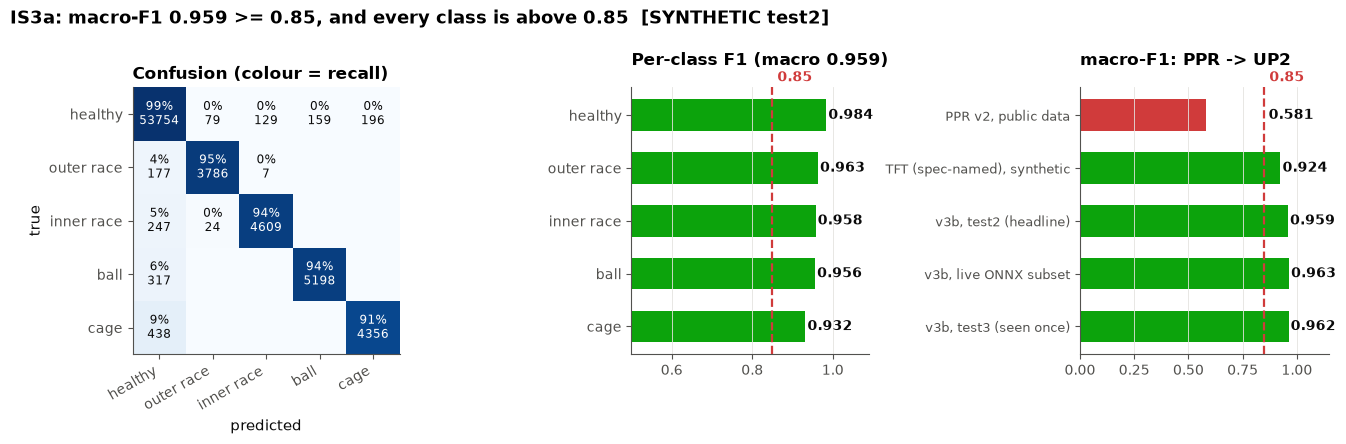

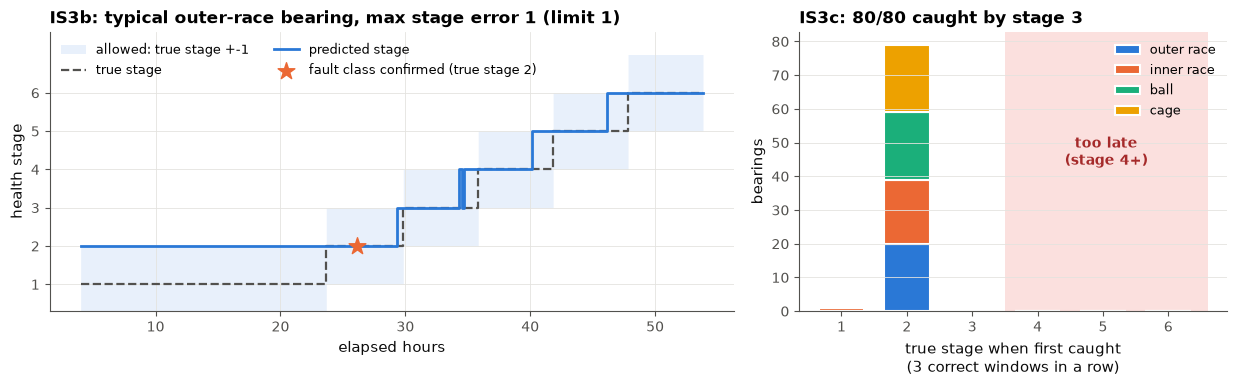

In [13]:
if R["status"] == "ok":
    ist = R["F1"] >= .85 and R["stage_max"] <= 1 and R["caught"] == R["rtf"]
    display(U.verdict("IS3", ist, f"macro-F1 {R['F1']:.3f} (>= 0.85); stage error max {R['stage_max']} (<= 1); caught by stage 3 {R['caught']}/{R['rtf']}", "[SYNTHETIC]"))
    display(U.table(pd.DataFrame([
        {"clause": "IS3a macro-F1 (5 classes)", "measured": f"{R['F1']:.4f}", "target": ">= 0.85", "status": "PASS" if R["F1"] >= .85 else "FAIL"},
        {"clause": "IS3b stage error, literal max", "measured": f"{R['stage_max']} (within +-1: {R['stage_within1']:.4f})", "target": "<= 1", "status": "PASS" if R["stage_max"] <= 1 else "FAIL"},
        {"clause": "IS3c faults caught by stage 3", "measured": f"{R['caught']}/{R['rtf']}", "target": "all", "status": "PASS" if R["caught"] == R["rtf"] else "FAIL"}]), status_cols=["status"], caption="IS3 clauses, fresh test2"))
    display(U.table(U.class_table(R["confusion"]), status_cols=["vs 0.85"], precision=3, caption=f"Per class (one-vs-rest, {R['windows']} test2 windows incl. healthy companions; F1 = 2PR/(P+R))"))
    cmp = [("PPR v2, public data", 0.581, False)]
    try:
        cmp[0] = ("PPR v2, public data", float(next(x["measured"] for x in (pj.get("verdicts") or pj["metrics"]["verdicts"]) if x["spec"] == "IS3a")), False)
    except Exception:
        pass
    if SN: cmp.append(("TFT (spec-named), synthetic", SN["F1"], SN["F1"] >= .85))
    cmp.append(("v3b, test2 (headline)", R["F1"], R["F1"] >= .85))
    if LE["status"] == "ok": cmp.append(("v3b, live ONNX subset", LE["cls"]["macro_f1"], LE["cls"]["macro_f1"] >= .85))
    if UC: cmp.append(("v3b, test3 (seen once)", UC["models"]["v3b"]["classification"]["macro_f1"], UC["models"]["v3b"]["classification"]["macro_f1"] >= .85))
    chart(U.fig_is3, "is3_confusion_f1.png", R["confusion"], R["per_class_f1"], R["F1"], cmp)
    try:
        fig, unit = U.fig_is3_stage(R["rr"], R["per_unit_caught"]); show(fig, "is3_stage_and_catch.png")
        display(HTML(f'<div style="font-size:12px;color:#52514e">left: bearing {unit}, the median-length outer-race test bearing (typical, not chosen by score). {U.tag("[SYNTHETIC]")}</div>'))
    except Exception as e:
        plt.close("all"); display(U.missing(f"stage chart: {e}"))
    display(U.reading(f"All three clauses pass on fresh synthetic data. The PPR's spec-named TFT had stage max error {SN.get('stage_max', '?')} (fails IS3b); the deployed v3b heads fix that. On public data IS3 still fails (history)." if SN else "All three clauses pass on fresh synthetic data."))
else:
    display(U.verdict("IS3", None, "re-score unavailable", "[SYNTHETIC]"))

### 8b. The counts behind IS3

In [14]:
if R["status"] == "ok":
    st = R["score"]["stage"]; cg = R["score"]["caught"]
    h = pd.DataFrame([{"|predicted - true| stage": int(k), "windows": v, "share": v / st["n_windows"]} for k, v in st["error_hist"].items()])
    h["status"] = ["PASS" if k <= 1 else "FAIL" for k in h["|predicted - true| stage"]]
    display(U.table(h, status_cols=["status"], fmt={"share": "{:.4f}"}, caption=f"IS3b stage error histogram over {st['n_windows']} run-to-failure windows"))
    display(U.table(pd.DataFrame([{"fault class": k, "caught by stage 3": v, "status": "PASS" if v.split("/")[0] == v.split("/")[1] else "FAIL"} for k, v in cg.get("per_class_by_stage3", {}).items()]),
                    status_cols=["status"], caption=f"IS3c per class (never caught: {cg.get('never_caught')})"))
    cm = R["confusion"]
    display(U.details("Raw confusion matrix (rows = true, columns = predicted)", body_html=U.table(pd.DataFrame(cm["matrix"], index=cm["labels"], columns=cm["labels"]).reset_index().rename(columns={"index": "true \\ pred"}), precision=0).to_html()))

|predicted - true| stage,windows,share,status
0,17208,0.6156,PASS
1,10747,0.3844,PASS


fault class,caught by stage 3,status
ball,20/20,PASS
cage,20/20,PASS
inner_race,20/20,PASS
outer_race,20/20,PASS


true \ pred,healthy,outer_race,inner_race,ball,cage
healthy,53754,79,129,159,196
outer_race,177,3786,7,0,0
inner_race,247,24,4609,0,0
ball,317,0,0,5198,0
cage,438,0,0,0,4356


## 9. S9 (dashboard >= 10 Hz) and IS1 (sensor to dashboard < 500 ms), live against the real backend

The backend starts from its Release build with `--Backend:ModelContractPath=model_contract_v3b.json` and the `up2` replay source
(`[SYNTHETIC]` stream); the .NET `DemoMeasure` client subscribes to the SignalR hub exactly like the Blazor dashboard (browser render time
not included). Same flags as `scripts/run-up2-demo.ps1`. Each backend is stopped by its own PID.

measure,value
client snapshots,600 in 20.0 s = 29.99 Hz
per-second counts (min / max),29 / 31
inter-arrival p50 / p95 / max,43.5 / 50.7 / 66.9 ms
build,"{'backend_s': 1.8, 'demomeasure_s': 1.3}"


backend stage,count,p50Ms,p95Ms,maxMs
broadcast,213.000,0.056,0.148,2.847
decode,213.000,0.003,0.020,4.152
features,213.000,0.031,0.088,43.916
inference,213.000,3.813,5.494,61.070
nhits_onnx,189.000,2.645,3.480,9.755
tft_onnx,189.000,1.051,1.442,17.608
total_ingest_to_broadcast,213.000,3.994,5.870,63.163


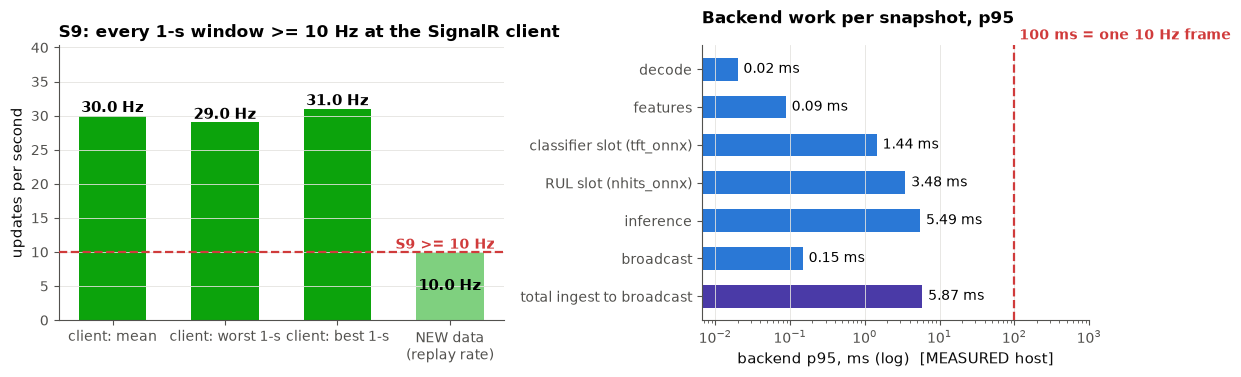

In [15]:
BLD = U.dotnet_ready()
S9 = U.s9_live(20) if BLD["status"] == "ok" else BLD
if S9["status"] == "ok":
    st = {s["stage"]: s for s in S9["metrics"]["stages"]}
    ok = S9["hz"] >= 10 and S9["per_sec_min"] >= 10
    display(U.verdict("S9", ok, f"{S9['hz']:.1f} Hz at the client, worst 1-s window {S9['per_sec_min']} (target >= 10 Hz); new data at 10 Hz", "[MEASURED host] [SYNTHETIC]"))
    U.record("S9", status="MET [MEASURED host]" if ok else "NOT MET", value=f"{S9['hz']:.1f} Hz client rate; worst 1-s window {S9['per_sec_min']}", target=">= 10 Hz",
             note="CAVEAT: the ~30 Hz is a client-side count of the backend's 50 ms re-broadcast timer; NEW data arrives at the 10 Hz replay rate (the spec minimum). SignalR .NET client, localhost, [SYNTHETIC] stream; browser render not measured (skipped by decision); spec also says physics RUL updated together; approval column still 'No'", rank=6, firm=True, achievable=9,
             step="Open the dashboard in a browser on a second device; a screen recording was not possible here (no ffmpeg/Playwright)", prov="[MEASURED host], [SYNTHETIC] stream", source="live: DemoMeasure rate")
    display(U.table(pd.DataFrame([{"measure": "client snapshots", "value": f"{S9['snapshots']} in {S9['seconds']:.1f} s = {S9['hz']:.2f} Hz"},
                                  {"measure": "per-second counts (min / max)", "value": f"{S9['per_sec_min']} / {S9['per_sec_max']}"},
                                  {"measure": "inter-arrival p50 / p95 / max", "value": f"{S9['gap_p50_ms']} / {S9['gap_p95_ms']} / {S9['gap_max_ms']} ms"},
                                  {"measure": "build", "value": str({k: v for k, v in BLD.items() if k != 'status'})}]), caption="S9 live measurement"))
    display(U.table(pd.DataFrame(st).T[["count", "p50Ms", "p95Ms", "maxMs"]].astype(float).round(3).reset_index().rename(columns={"index": "backend stage"}), precision=3, caption="Backend /api/metrics per stage, ms [MEASURED host]"))
    chart(U.fig_s9, "s9_rate.png", S9, st, 10.0)
    display(U.details("S9 caveat (read before quoting 30 Hz)", body_md="The ~30 Hz is a client-side count of the backend's **50 ms re-broadcast timer**; **new data** arrives at the **10 Hz** replay rate (the spec minimum). SignalR .NET client on localhost, `[SYNTHETIC]` stream; browser render not measured (skipped by decision); the spec also asks for the physics RUL to be updated together; the approval column is still 'No'."))
else:
    display(U.verdict("S9", None, "live backend unavailable; stored value used if present", "[MEASURED host]")); display(U.missing(S9))
    v = integ.get("s9_hz")
    if v: U.record("S9", status="MET [MEASURED host]" if v >= 10 else "NOT MET", value=f"{v:.1f} Hz (STORED)", target=">= 10 Hz", rank=6, achievable=9, step="live backend cell failed; re-run", prov="[MEASURED host] stored", source=U.stamp(int_p))
    else: U.record("S9", status="NOT EVIDENCED (no live run, no stored value)", rank=0)

leg,p50 ms,p95 ms,max ms,provenance
Wi-Fi hop (injected delay realised),43.8,63.7,64.1,[SIMULATION] 10-60 ms jitter
UDP + backend + SignalR client receive,5.0,8.0,12.8,[MEASURED host] localhost
per-window sum: measured legs + COE STM32 pessimistic (verdict),77.0,97.9,104.9,mixed incl. [CALCULATED]
per-window sum: measured legs + COE host,53.9,76.3,85.4,[MEASURED host + SIMULATION]
"COE t20 -> payload, STM32 pessimistic (10 cyc/flop, 480 MHz assumed)",-,28.4,28.4,[CALCULATED]


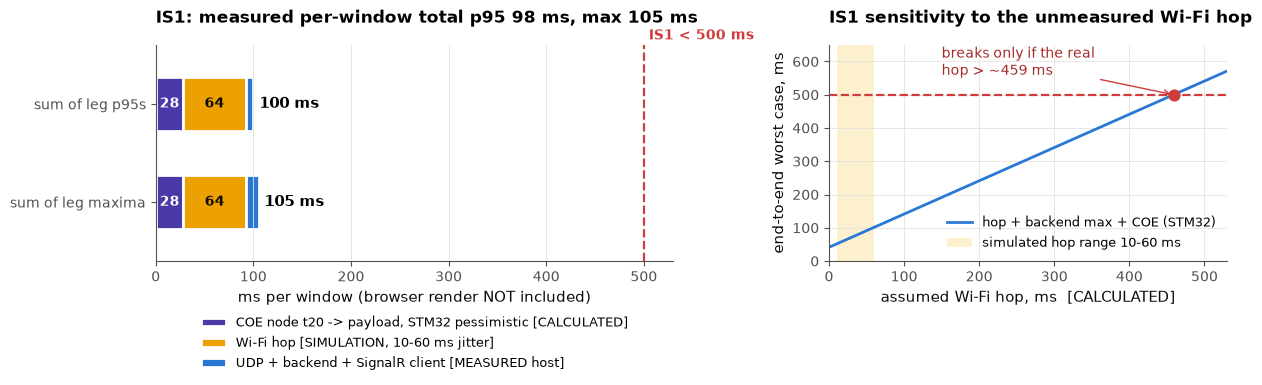

Wi-Fi hop assumed,COE leg ms,backend p95 ms,backend max ms,total (p95 backend) ms,total (max backend) ms,status
sim 10-60 ms (max),28.4,8.0,12.8,96.4,101.2,PASS
100 ms,28.4,8.0,12.8,136.4,141.2,PASS
300 ms,28.4,8.0,12.8,336.4,341.2,PASS


Leg,p50 ms,p95 ms,max ms,Provenance
Wi-Fi hop (injected delay realised),43.8,63.7,64.1,[SIMULATION] assumed 10-60 ms jitter
"UDP + backend (decode, features, 2x ONNX, SignalR) + client receive",5.0,8.0,12.8,[MEASURED host] localhost; not the target server / Pi 5
Sender window-close -> client receive (two rows above),48.5,69.5,76.5,[MEASURED host + SIMULATION]
Stage,p50 ms,p95 ms,max ms,Provenance
"COE t20 -> payload ready, host PC (Python/NumPy; worst of 1750/3600 rpm)",5.3,6.8,9.0,"[MEASURED host], not STM32"
"COE t20 -> payload ready, STM32 pessimistic (10 cyc/flop, 480 MHz M7 assumed, incl. wait for last DMA block)",-,28.4,28.4,[CALCULATED] (nominal 2 cyc/flop: 12.5 ms)
Per-window sum: measured legs + COE host (p50 / p95 / max),53.9,76.3,85.4,[MEASURED host + SIMULATION]
Per-window sum: measured legs + COE STM32 pessimistic (conservative),77.0,97.9,104.9,mixed incl. [CALCULATED]


In [16]:
I1 = U.is1_live(n=120) if BLD["status"] == "ok" else BLD
coe_leg = 28.4
if I1["status"] == "ok":
    lg = I1["legs"]; s = lg["sum_stm32"]
    display(U.verdict("IS1", s["max"] < 500, f"per-window p95 {s['p95']:.1f} ms, max {s['max']:.1f} ms vs target < 500 ms (Wi-Fi hop simulated, STM32 leg calculated)", "[MEASURED host] [SIMULATION] [CALCULATED]"))
    U.record("IS1", status="MET [SIMULATION]" if s["max"] < 500 else "NOT MET", value=f"p95 {s['p95']:.1f} ms, max {s['max']:.1f} ms (STM32-pessimistic COE + simulated Wi-Fi 10-60 ms + measured backend)", target="< 500 ms",
             note="Wi-Fi hop is SIMULATED, STM32 leg CALCULATED, browser render not included. Only a Wi-Fi hop of ~380 ms or more would break the budget (sensitivity table below). Rank 9 as a live end-to-end SIMULATION demo (injected Wi-Fi hop, calculated STM32 leg: assumed legs disclosed, so not counted firm)", rank=9, firm=False, achievable=9,
             step="Measure the real ESP32-C6 -> AP -> server hop and the STM32 leg; show the browser update", prov="[MEASURED host] + [SIMULATION] Wi-Fi + [CALCULATED] STM32", source="live: DemoMeasure is1; " + U.stamp(int_p))
    names = {"wifi": ("Wi-Fi hop (injected delay realised)", "[SIMULATION] 10-60 ms jitter"), "backend": ("UDP + backend + SignalR client receive", "[MEASURED host] localhost"),
             "sum_host": ("per-window sum: measured legs + COE host", "[MEASURED host + SIMULATION]"), "sum_stm32": ("per-window sum: measured legs + COE STM32 pessimistic (verdict)", "mixed incl. [CALCULATED]")}
    tl = pd.DataFrame([{"leg": names[k][0], "p50 ms": v["p50"], "p95 ms": v["p95"], "max ms": v["max"], "provenance": names[k][1]} for k, v in lg.items() if k in names])
    tl.loc[len(tl)] = {"leg": "COE t20 -> payload, STM32 pessimistic (10 cyc/flop, 480 MHz assumed)", "p50 ms": None, "p95 ms": coe_leg, "max ms": coe_leg, "provenance": "[CALCULATED]"}
    display(U.table(tl, precision=1, caption=f"IS1 legs, live run n={I1['n']} windows at 20 Hz"))
    chart(U.fig_is1, "is1_budget.png", lg, coe_leg, lg["backend"]["max"])
    try:
        tab, brk = U.is1_sensitivity(lg["backend"]["p95"], lg["backend"]["max"], coe_leg)
        display(U.table(tab.rename(columns={"< 500 ms": "status"}).assign(status=lambda d: d.status.map({"yes": "PASS", "NO": "FAIL"})), status_cols=["status"], precision=1,
                        caption=f"[CALCULATED] sensitivity: the 500 ms budget breaks only if the real Wi-Fi hop exceeds ~{brk:.0f} ms (worst-case backend)"))
    except Exception as e:
        display(U.missing(f"sensitivity: {e}"))
    display(U.details("IS1 live report (DemoMeasure) and what is NOT measured", body_md=I1["report_md"][-1700:] + "\n\n**Not measured:** real Wi-Fi latency/jitter, STM32 timing, browser (Blazor WASM) render time, final server (laptop vs Raspberry Pi 5)."))
else:
    display(U.verdict("IS1", None, "live backend unavailable; stored value used if present", "[MEASURED host]")); display(U.missing(I1))
    v = integ.get("is1")
    if v: U.record("IS1", status="MET [SIMULATION]" if v["max"] < 500 else "NOT MET", value=f"p95 {v['p95']:.1f} / max {v['max']:.1f} ms (STORED)", target="< 500 ms", rank=6, achievable=9, step="re-run live cell", prov="[MEASURED host]+[SIMULATION]+[CALCULATED] stored", source=U.stamp(int_p))
    else: U.record("IS1", status="NOT EVIDENCED (no live run, no stored value)", rank=0)

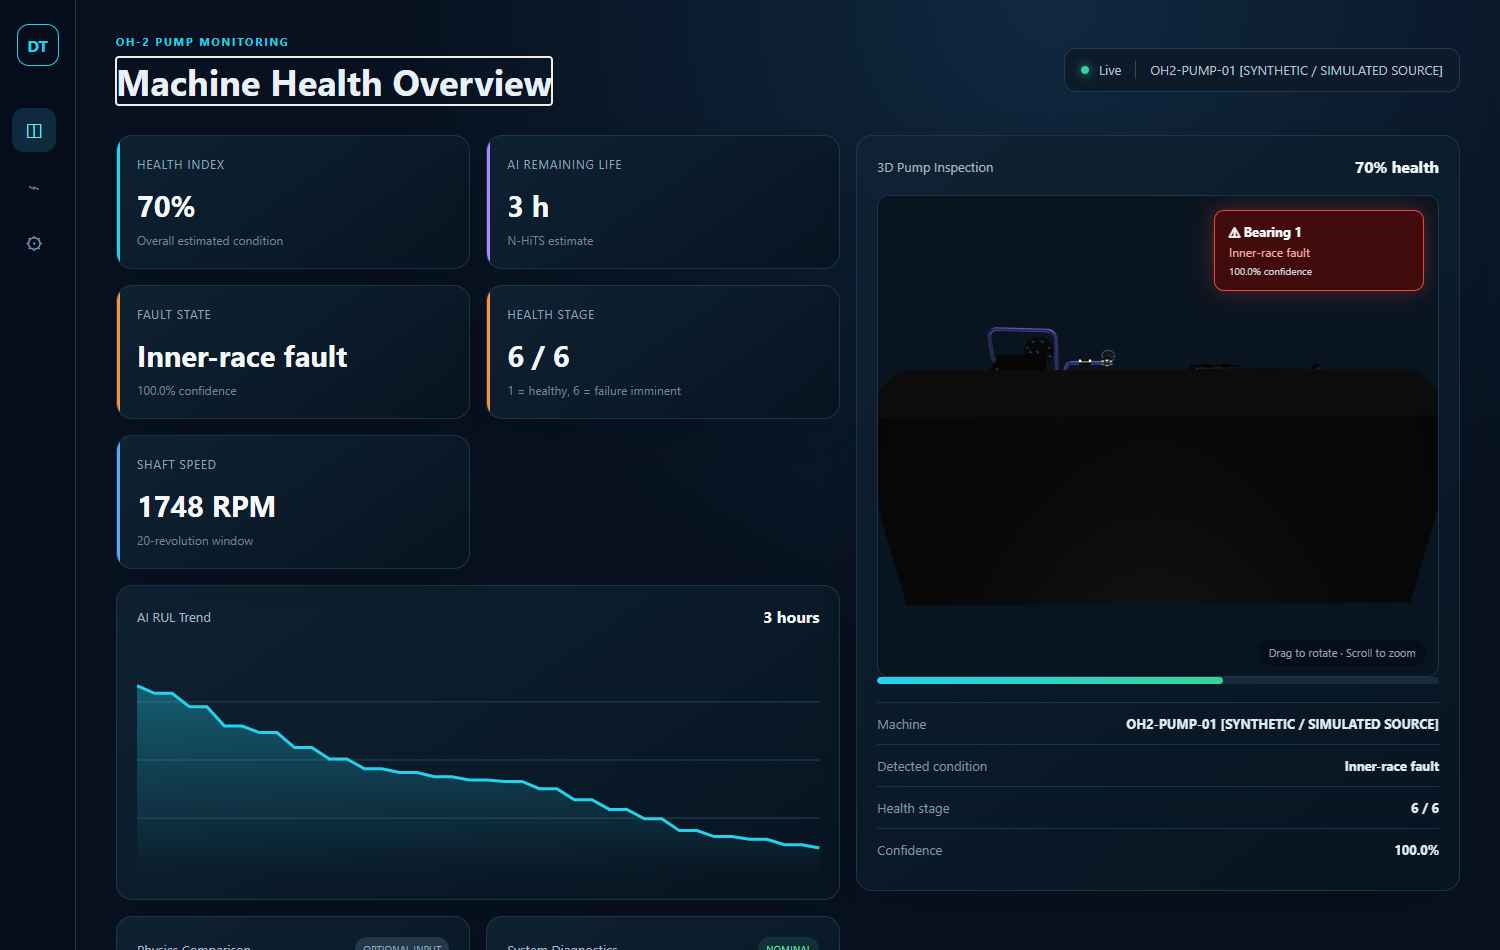

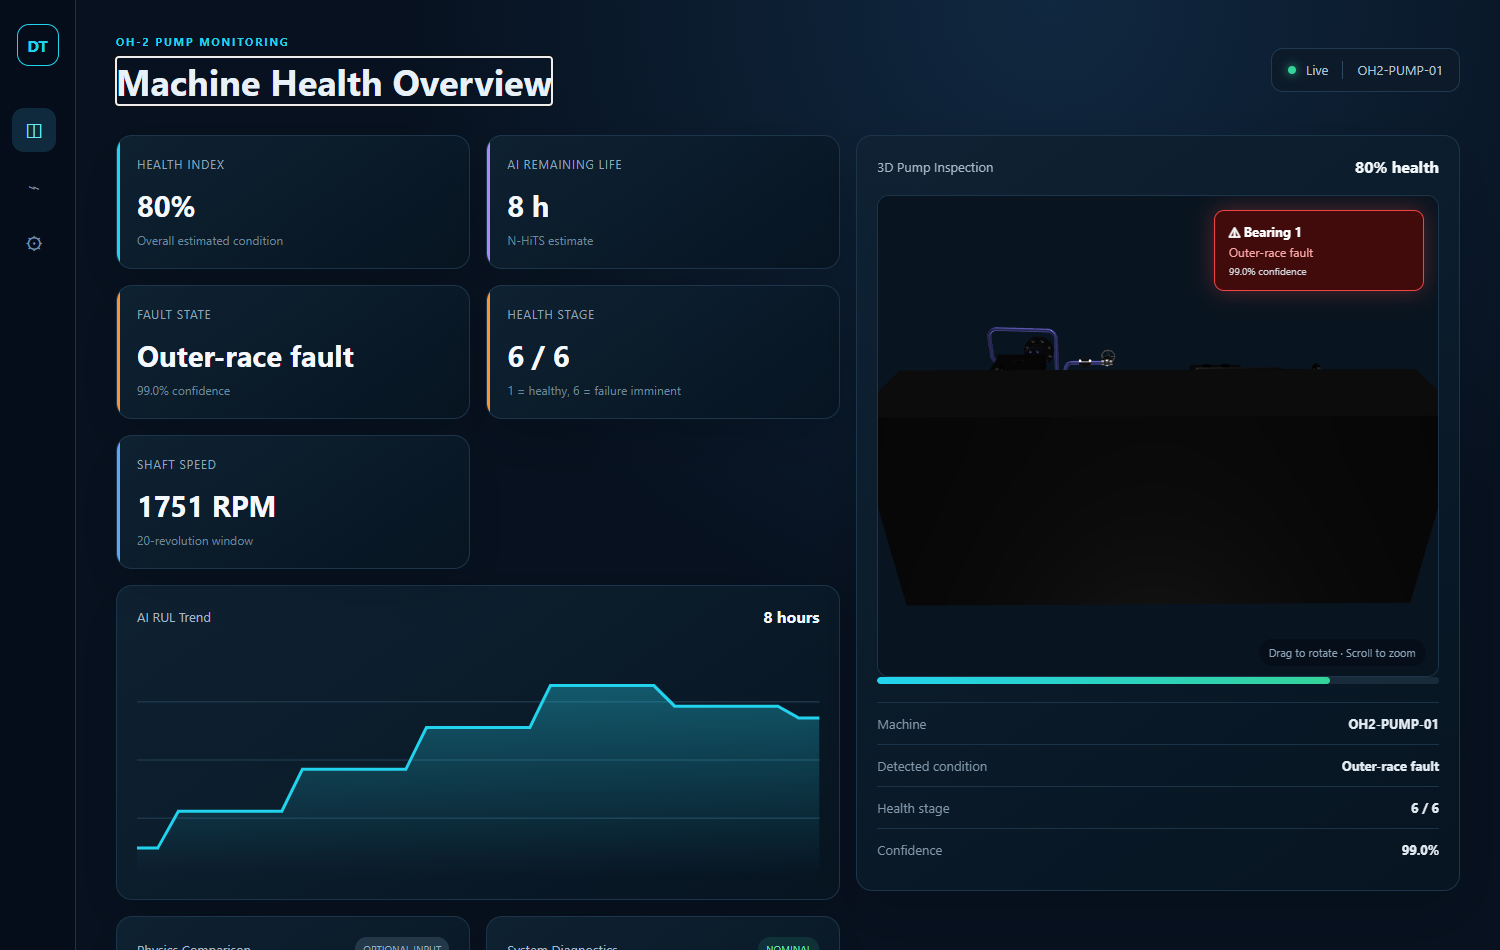

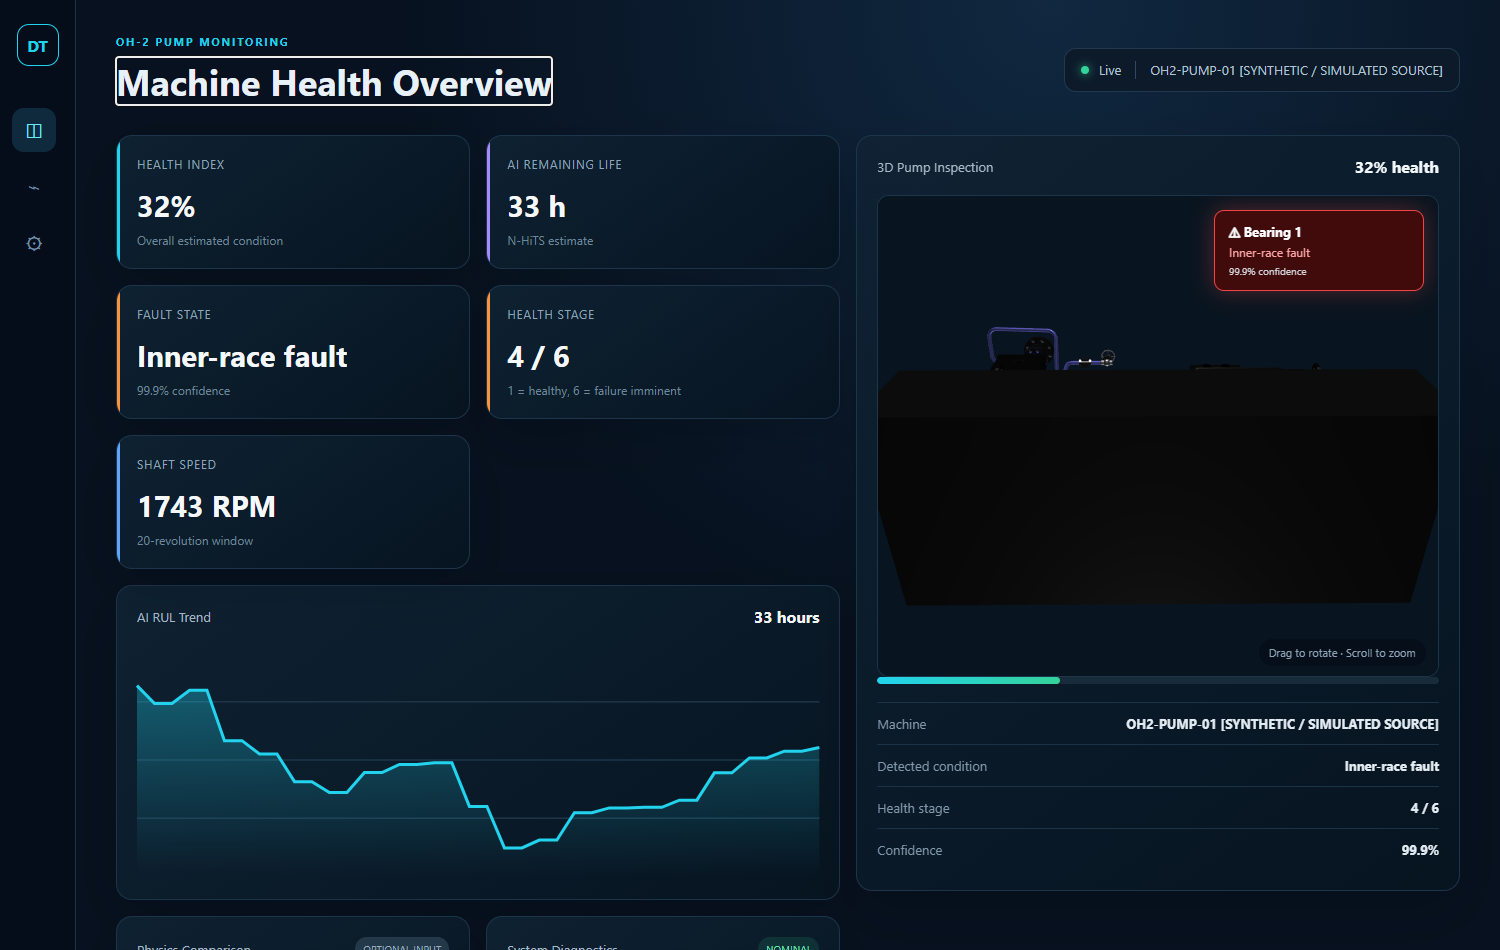

In [17]:
dash = sorted(U.EVIDENCE.glob("dashboard_up2_*.png"))
if dash:
    display(HTML('<div style="font-weight:700;font-size:14px">The dashboard (picture of the demo; the data for S9/IS1 are above) ' + U.tag("[SYNTHETIC / SIMULATED SOURCE]") + '</div>'))
    for p in dash[-3:]:
        display(HTML(f'<div style="font-size:12px;color:#52514e;margin-top:8px">{U._esc(U.stamp(p))}</div>')); display(Image(filename=str(p), width=900))
else:
    display(U.missing("evidence/dashboard_up2_*.png (dashboard screenshot not on disk yet)"))
display(U.details("Video of the demo", body_md="NOT produced. No ffmpeg or Playwright is installed in this environment, so a reliable screen recording was not possible. Run `./scripts/run-up2-demo.ps1` and open http://localhost:5080/ to see it live."))

## 10. IS2: physics-AI RUL agreement under the reworded spec (wording v2)

**Wording v2** (from the coach feedback of 2026-10-25; the v1 text is kept in `Specifications.md`): for the faulted bearing of every
run-to-failure run, over every window in true health stages 1-3 after the AI warm-up, e = |RUL_physics - RUL_AI| / L_ref (L_ref = the bearing's
reference rated life), and **(a)** the median over bearings of each bearing's median e <= **18 %**, **(b)** the 95th percentile over bearings of each
bearing's 95th-percentile e <= **63 %**. Thresholds were **frozen on validation sets only** (`synth_v3_val4`, `synth_v3_val2`) and committed
(355831c) **before** `synth_v3_test4` was scored once. **The official xlsx has NOT been updated yet**: the team must paste the text from `Specifications.md`.

<div style="border:1px solid #fab219;border-left:8px solid #fab219;background:#fdf0cf;border-radius:6px;padding:6px 12px;font-size:13.5px">
<b>&#9680; Caveat, read before quoting the PASS (tell the coach):</b> clause (a) mostly measures agreement with the twin's rated-life <i>prior</i>;
an exact AI would itself score 18.1 % on (a). Details in the fold below.</div>

<details><summary><b>Full caveat (all disclosures)</b></summary>

- Clause (a) mostly measures **agreement with the twin's rated-life PRIOR**: about 97 % of stage 1-3 windows use the prior, because the stiffness drop is <= 5 % in stages 1-3, below the identification noise (~6 % at 1750 rpm, ~25 % at 3600 rpm). An **exact** AI (RUL_AI = truth) would itself score **18.1 %** on clause (a), i.e. it would FAIL it.
- The residual as a flag for a bad AI estimate is weak: **AUROC 0.55**. Clause (b) and the wrong-AI controls are the discriminating parts.
- The data are circular and synthetic (the stiffness trajectory and the accelerometer features come from one damage variable).
- Wording v2 is **not yet confirmed in the official xlsx**; the team must edit it.
- On the rig, `L_ref` becomes the ISO 281 rated life, and the prior and the thresholds must be re-fit on rig validation data.
</details>

model / run,(a) median %,(b) p95 %,verdict,v1 literal max %,provenance
"v3b deployed, stored report (test4, scored once)",16.3,49.2,PASS,233.4,[SYNTHETIC]+[SIMULATION]
"v3b, LIVE re-score of saved predictions, twin physics recomputed (26.7 s)",16.3,49.2,PASS,233.4,[SYNTHETIC]+[SIMULATION]
"v3b, LIVE deployed ONNX engine on 20 faulted bearings (51.8 s)",14.8,51.8,PASS,-,[SYNTHETIC]+[SIMULATION] live
"v3c research (physics-informed, not deployed)",18.3,47.8,FAIL,216.1,[SYNTHETIC]+[SIMULATION]
exact AI (RUL_AI = truth): the physics floor,18.1,48.5,FAIL,-,[CALCULATED] same windows


control,(a) median %,(b) p95 %,verdict,expected
AI x 1.5 (optimistic bias),21.6,91.2,FAIL,FAIL
AI x 0.6 (pessimistic bias),29.4,60.3,FAIL,FAIL
AI + 0.3 L_ref,23.0,79.1,FAIL,FAIL
AI time-reversed within bearing,17.8,66.2,FAIL,FAIL
AI = 0.5 L_ref constant,18.5,42.7,FAIL,FAIL
"AI = truth x lognormal(0, 0.5) noise",25.7,172.4,FAIL,FAIL


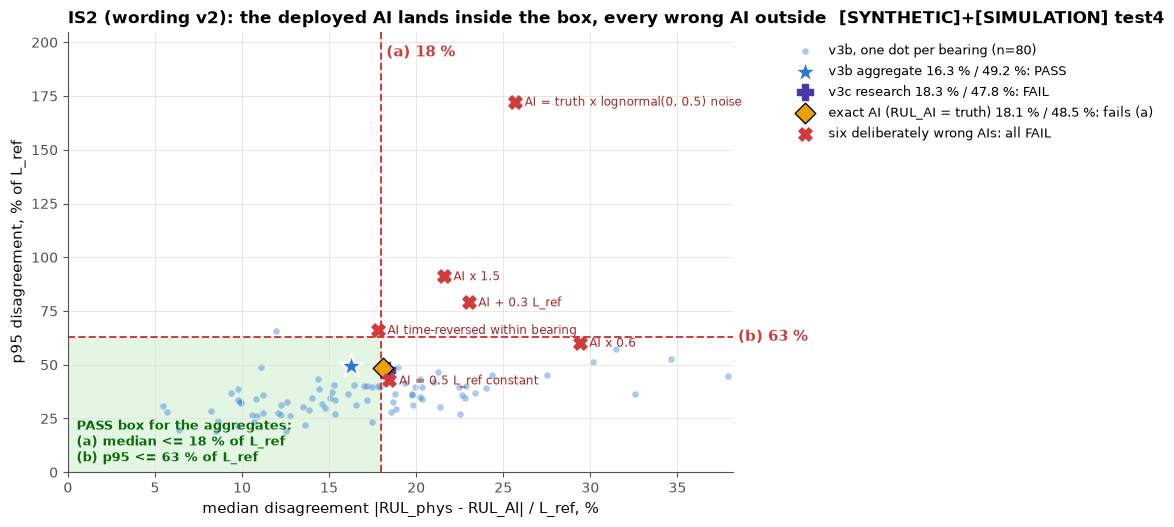

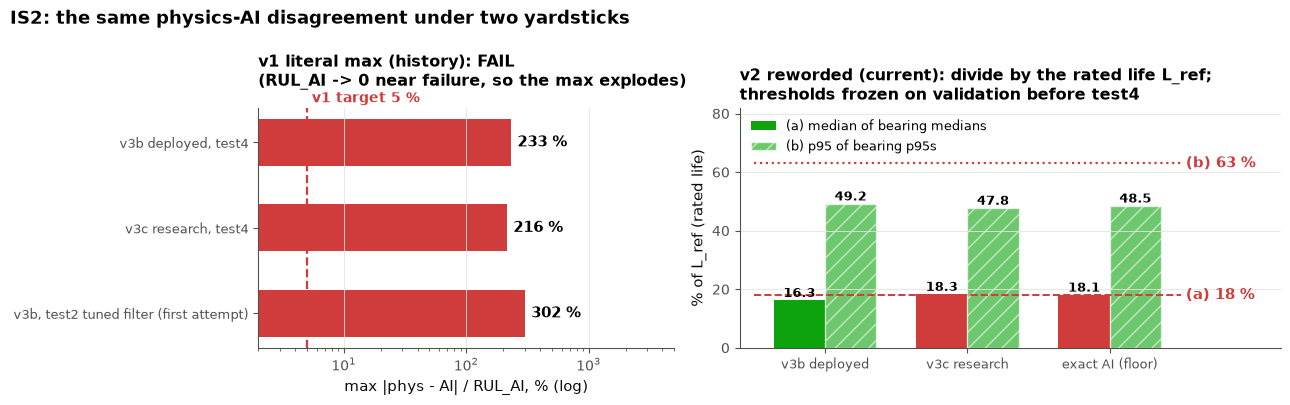

In [18]:
UD = U.load_json(up2d_p)
IR = U.is2_v2_rescore("test4")
LS = U.is2_live_subset(step=4)
ok_v2 = bool(UD) and UD["models"]["v3b"]["v2"]["verdict"] == "PASS" and IR["status"] == "ok" and IR["models"]["v3b"]["v2"]["verdict"] == "PASS" and all(x["verdict"] == "FAIL" for x in IR["controls"])
sub_ok = LS["status"] == "ok" and LS["v2"]["verdict"] == "PASS"
if UD:
    b = UD["models"]["v3b"]["v2"]
    display(U.verdict("IS2 (v2)", ok_v2, f"median {100*b['MED']:.1f} % (<= 18) and p95 {100*b['P95']:.1f} % (<= 63) of L_ref; six wrong-AI controls all FAIL", "[SYNTHETIC] [SIMULATION]",
                      note="design level: wording v2 not yet in the official xlsx; clause (a) mostly measures agreement with the twin's prior (see caveat)"))
    U.record("IS2", status="MET [SYNTHETIC]+[SIMULATION] under wording v2 (pending team/xlsx confirmation)" if ok_v2 else "NOT MET [SIMULATION]",
             value=f"v2: median {100*b['MED']:.1f} % (<=18), p95 {100*b['P95']:.1f} % (<=63) of L_ref; v1 literal max {100*UD['models']['v3b']['v1']['max']:.0f} % (FAIL, history); v3c research median {100*UD['models']['v3c']['v2']['MED']:.1f} % FAIL",
             target="v2: median <= 18 %, p95 <= 63 % of L_ref",
             note="CAVEAT: clause (a) mostly measures agreement with the twin's rated-life prior (~97 % of windows); an exact AI scores 18.1 % on (a) and would FAIL it; residual-as-flag AUROC 0.55; circular synthetic data; wording v2 not yet in the official xlsx; on the rig L_ref = ISO 281 rated life and prior/thresholds must be re-fit. Thresholds frozen on validation before test4 (scored once); six wrong-AI controls all FAIL.",
             rank=9 if sub_ok else 6, firm=False, achievable=9, deployed="deployed v3b heads (verdict); v3c research only",
             specnamed="v1 literal (max <= 5 %): v3b 233 %, v3c 216 % FAIL",
             step="Team pastes wording v2 into the xlsx and tells the coach the clause-(a) limitation; on the rig re-fit L_ref (ISO 281), the prior and the thresholds",
             prov="[SYNTHETIC] synth_v3_test4 + [SIMULATION] FE twin (assumed geometry)", source=U.stamp(up2d_p) + "; IS2 rank: " + ("9 for the live subset run (deployed engine + twin), 6 for the full 80-bearing re-score of saved AI predictions" if sub_ok else "6 (saved predictions re-scored)"))
    c = UD["models"]["v3c"]; fl = UD["floor_perfect_ai"]
    rows = [{"model / run": "v3b deployed, stored report (test4, scored once)", "(a) median %": 100*b["MED"], "(b) p95 %": 100*b["P95"], "verdict": b["verdict"], "v1 literal max %": 100*UD["models"]["v3b"]["v1"]["max"], "provenance": "[SYNTHETIC]+[SIMULATION]"}]
    if IR["status"] == "ok":
        v = IR["models"]["v3b"]["v2"]
        rows.append({"model / run": f"v3b, LIVE re-score of saved predictions, twin physics recomputed ({IR['seconds']} s)", "(a) median %": 100*v["MED"], "(b) p95 %": 100*v["P95"], "verdict": v["verdict"], "v1 literal max %": 100*IR["models"]["v3b"]["v1"]["max"], "provenance": "[SYNTHETIC]+[SIMULATION]"})
    if LS["status"] == "ok":
        rows.append({"model / run": f"v3b, LIVE deployed ONNX engine on {LS['n_bearings']} faulted bearings ({LS['seconds']} s)", "(a) median %": 100*LS["v2"]["MED"], "(b) p95 %": 100*LS["v2"]["P95"], "verdict": LS["v2"]["verdict"], "v1 literal max %": None, "provenance": "[SYNTHETIC]+[SIMULATION] live"})
    rows += [{"model / run": "v3c research (physics-informed, not deployed)", "(a) median %": 100*c["v2"]["MED"], "(b) p95 %": 100*c["v2"]["P95"], "verdict": c["v2"]["verdict"], "v1 literal max %": 100*c["v1"]["max"], "provenance": "[SYNTHETIC]+[SIMULATION]"},
             {"model / run": "exact AI (RUL_AI = truth): the physics floor", "(a) median %": 100*fl["MED"], "(b) p95 %": 100*fl["P95"], "verdict": fl["verdict"], "v1 literal max %": None, "provenance": "[CALCULATED] same windows"}]
    display(U.table(pd.DataFrame(rows), status_cols=["verdict"], precision=1, caption=f"IS2 wording v2 on test4 (hash {UD['meta']['table_hash']}, {b['n_windows']} windows, {b['n_bearings']} bearings); thresholds (a) 18 %, (b) 63 %"))
    ctr = pd.DataFrame(IR["controls"] if IR["status"] == "ok" else UD["controls"])[["control", "MED", "P95", "verdict"]].assign(MED=lambda d: 100*d.MED, P95=lambda d: 100*d.P95)
    ctr["expected"] = "FAIL"
    display(U.table(ctr.rename(columns={"MED": "(a) median %", "P95": "(b) p95 %"}), status_cols=["verdict"], precision=1, caption="Negative controls: deliberately wrong AIs on the same windows (a good spec must fail them all)"))
    if IR["status"] == "ok":
        chart(U.fig_is2_scatter, "is2_v2_scatter.png", IR["pb_v3b"], IR["models"]["v3b"]["v2"]["MED"], IR["models"]["v3b"]["v2"]["P95"], UD["frozen"]["T_MED"], UD["frozen"]["T_P95"],
              IR["controls"], IR["floor_perfect_ai"], IR["models"]["v3c"]["v2"])
    else:
        display(U.missing(IR))
    v1 = [("v3b deployed, test4", 100*UD["models"]["v3b"]["v1"]["max"]), ("v3c research, test4", 100*c["v1"]["max"])]
    if resid:
        h = U.residual_headline(resid, res_p.with_suffix(".md"))
        if isinstance(h.get("max"), (int, float)): v1.append(("v3b, test2 tuned filter (first attempt)", h["max"]))
    chart(U.fig_is2_v1v2, "is2_v1_vs_v2.png", v1, [("v3b deployed", 100*b["MED"], 100*b["P95"]), ("v3c research", 100*c["v2"]["MED"], 100*c["v2"]["P95"]),
          ("exact AI (floor)", 100*fl["MED"], 100*fl["P95"])], UD["frozen"]["T_MED"], UD["frozen"]["T_P95"])
    vv = UD["validation"]["values"]
    display(U.details("Wording texts, frozen thresholds and validation values", body_md=f"**Wording v2:** {UD['v2_text']}\n\n**Wording v1 (kept, superseded):** {UD['v1_text']}\n\n"
                      f"**Frozen (validation only):** {UD['frozen']}; rule: {UD.get('validation', {}).get('chosen', {}).get('rule')}\n\n**Validation values (fraction of L_ref, (MED, P95)):** "
                      + str({n: {k: (round(v['MED'], 3), round(v['P95'], 3)) for k, v in d.items()} for n, d in vv.items()})
                      + f"\n\n**v1 literal on test3 (history):** " + str({k: f"{100*v:.0f} %" for k, v in UD["history_v1"].items() if isinstance(v, float)})
                      + f"\n\n**Residual as bad-estimate flag (v3b):** AUROC {UD['models']['v3b']['flag_auroc']['auroc']:.3f}; physics = prior on {100*b['share_physics_is_prior']:.1f} % of windows."))
    display(U.reading("Under wording v2 the deployed AI passes both clauses on a fresh set while all six deliberately wrong AIs fail, so the spec discriminates. It is counted MET at **design level** only: wording v2 is not yet in the official xlsx and clause (a) mostly measures agreement with the twin's prior."))
else:
    display(U.verdict("IS2 (v2)", None, "reports/up2d_is2_2*.json missing; v1 history below decides", "[SIMULATION]"))
    if LS["status"] != "ok": display(U.missing(LS))

### 10b. History: IS2 under the original literal wording v1 (max <= 5 %), NOT MET

Kept for transparency (never presented as met). Stored `[SIMULATION]`+`[SYNTHETIC]` reports with command and seed; `v3c` is a **research
artifact, NOT the deployed model** (v3b is deployed; v3c is 9.5 MB and not ported to C#). Re-run: `cd AI-engine; .venv/Scripts/python.exe -m aiengine.up2_residual`.

In [19]:
rows = []
if resid:
    h = U.residual_headline(resid, res_p.with_suffix(".md"))
    mx = h["max"]
    rows.append({"attempt": "v3b on test2, tuned filter (first attempt)", "max %": mx, "p95 %": h.get("p95"), "median %": h.get("median"), "share <= 5 %": h.get("share5"), "coverage %": h.get("coverage"), "verdict": "FAIL", "file": res_p.name})
    if "IS2" not in U.REG:
        U.record("IS2", status="NOT MET [SIMULATION]", value=(f"v1 literal, test2 tuned-filter, history: max {mx:.1f} % (p95 {h.get('p95', float('nan')):.1f} %, median {h.get('median', float('nan')):.1f} %; windows <=5 %: {h.get('share5', float('nan')):.1f} %)" if isinstance(mx, (int, float)) else "see report"), target="<= 5 %",
                 note="best tuned configuration still far above 5 %; floor from the AI RUL error alone is 15 % median. Open physics-role contradiction: ICS doc s2 (physics as AI input vs independent physics RUL compared via residual)", rank=6, achievable=9,
                 step="Run `python -m aiengine.up2_residual` live in the demo; a PASS needs an independent physics RUL plus an AI RUL within ~5 % of truth, i.e. a spec-definition decision by team/reviewer",
                 prov="[SIMULATION] + [SYNTHETIC]", source=U.stamp(res_p))
if UC:
    i2 = UC["is2"]; ab = UC["ablation"]
    for k, lab in (("v3c", "v3c on test3, AI consumes physics (consistency reading)"), ("ablation", "v3c without physics on test3 (independent)"), ("v3b", "deployed v3b on test3 (independent)")):
        r = i2[k]["residual"]
        rows.append({"attempt": lab, "max %": 100 * r["max"], "p95 %": 100 * r["p95"], "median %": 100 * r["median"], "share <= 5 %": 100 * r["share_le_5pct"] if "share_le_5pct" in r else 100 * r.get("frac_le_5pct", float("nan")),
                     "coverage %": 100 * i2[k]["coverage"], "verdict": "FAIL" if r["max"] > 0.05 else "PASS", "file": up2c_p.name})
    if "IS2" not in U.REG:
        rv = i2["v3c"]["residual"]; ro = i2["v3b"]["residual"]
        U.record("IS2", status="NOT MET [SIMULATION]",
                 value=f"literal max residual: independent {100*ro['max']:.1f} % (p95 {100*ro['p95']:.1f}, median {100*ro['median']:.1f}); v3c consistency {100*rv['max']:.1f} % (p95 {100*rv['p95']:.1f}, median {100*rv['median']:.1f}); ablation reading {100*ab['relative_improvement_vs_ablation']:.1f} % relative S7 gain",
                 target="max <= 5 % (or Sept-3 ablation: >= 15 % relative gain)", rank=6, achievable=9,
                 note="NOT MET under every reading. v3c is a research artifact (not deployed, not in C#). Physics coverage 100 % only through a physics PRIOR (96.7 % of windows), not through identification. Decision for team/coach: IS2 wording needs renegotiation.",
                 step="Team/coach decision on the IS2 definition (e.g. p95/median consistency band or the ablation criterion); rig data for an independent physics estimate",
                 prov="[SYNTHETIC] synth_v3_test3 + [SIMULATION] FE twin (assumed geometry)", source=U.stamp(up2c_p) + "; " + U.stamp(res_p))
if rows:
    display(U.table(pd.DataFrame(rows), status_cols=["verdict"], precision=1, caption="IS2 v1 literal (max <= 5 %), history: every attempt FAILS"))
if UC:
    ab = UC["ablation"]
    display(HTML(f'<div style="font-size:12.5px">{U.pill("NOT MET", "Sept-3 ablation reading: FAIL")} S7 v3c {ab["S7_v3c"]:.2f} % vs without physics {ab["S7_ablation"]:.2f} % = {100*ab["relative_improvement_vs_ablation"]:.1f} % relative gain (target >= 15 %) {U.tag("[SYNTHETIC]+[SIMULATION]")}</div>'))
if resid:
    md_p = res_p.with_suffix(".md")
    if md_p.exists():
        txt = md_p.read_text(encoding="utf-8"); i = txt.find("## Verdict")
        display(U.details(f"Stored v1 report verdict ({md_p.name})", body_md=txt[i:i + 1500]))
display(U.details("Why IS2 v1 cannot pass in this setup (structural, not a tuning gap), and the options that led to wording v2", body_md="""
- In the simulator the stiffness drops by less than 3 % during stages 1-3, below the identification noise, so the physics side has almost no signal there.
- 3600 rpm windows fail the identification gate (stiffness is weakly observable above the bearing mode); that is why coverage reaches 100 % only through a physics prior (96.7 % of windows use it).
- Both estimators carry their own error against truth (AI median 22 %, physics median 28 % on these windows), so a bound on the **maximum** relative difference of 5 % cannot hold: even a perfect physics RUL would leave a 15 % median residual.

**Decision options given to team / coach:** (a) a consistency band on p95 or median instead of the max (adopted as wording v2, section 10); (b) the Sept-3 ablation criterion (physics inputs improve S7 by >= 15 % relative; currently 3.4 %); (c) keep the literal spec and record it as not met until rig data exists.
"""))

attempt,max %,p95 %,median %,share <= 5 %,coverage %,verdict,file
"v3b on test2, tuned filter (first attempt)",302.1,90.8,39.0,5.3,57.6,FAIL,up2_residual_20261024T173626Z.json
"v3c on test3, AI consumes physics (consistency reading)",245.6,77.9,33.4,9.0,100.0,FAIL,up2c_spec_check_20261024T175404Z.json
v3c without physics on test3 (independent),243.4,79.3,29.5,9.5,100.0,FAIL,up2c_spec_check_20261024T175404Z.json
deployed v3b on test3 (independent),244.6,78.5,29.3,9.7,100.0,FAIL,up2c_spec_check_20261024T175404Z.json


Reading,Value,Target,Verdict
"IS2 literal: max per-window residual, stages 1-3, nominal, tuned filter",302.1 %,<= 5 %,FAIL
p95 residual (alternative reading),90.8 %,<= 5 %,FAIL
median / mean residual,39.0 % / 43.6 %,-,-
share of windows with residual <= 5 %,5.3 %,-,-
physics coverage (stage 1-3 windows with a physics RUL),57.6 %,-,-


## 11. Tests and ONNX / C# parity (live)

The Python test suites of the COE pipeline and the UP2 models run live; the C# backend's golden-vector parity tests for the deployed v3b contract
(and the COE-source v3b_coe contract) replay the Python engine's recorded outputs through the C# feature engineering, ONNX and post-process.

suite,status,passed,failed,summary,seconds
pytest tests/coe,PASS,24,0,24 passed in 2.94s,4.0
pytest tests/up2 + tests/twin_up2,PASS,29,0,29 passed in 67.92s (0:01:07),70.2
dotnet: C# golden parity v3b + v3b_coe,PASS,4,0,"4 passed, 0 failed",4.2


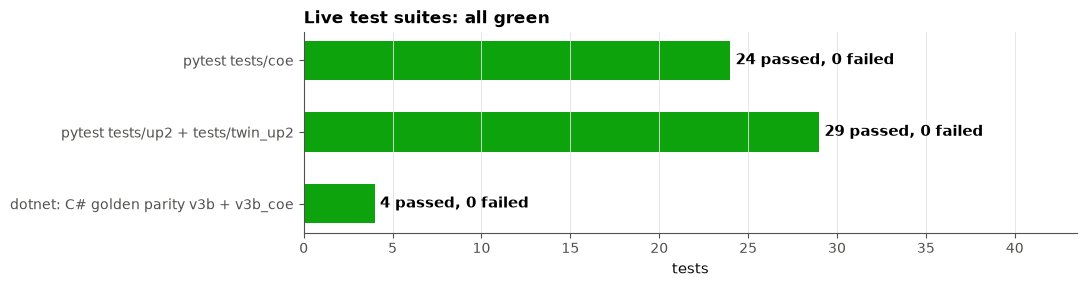

'evidence\\up2_figures\\tests.png'

In [20]:
T = {"pytest tests/coe": U.pytest_live(["tests/coe"]), "pytest tests/up2 + tests/twin_up2": U.pytest_live(["tests/up2", "tests/twin_up2"])}
if P.dotnet_path() is not None:
    try:
        _, tot = P.dotnet_test("FullyQualifiedName~GoldenV3bParityTests|FullyQualifiedName~GoldenV3bCoeParityTests", project="tests/DigitalTwin.Backend.Tests")
        T["dotnet: C# golden parity v3b + v3b_coe"] = {"status": "ok", **tot, "tail": f"{tot['passed']} passed, {tot['failed']} failed", "seconds": tot.get("elapsed_s")}
    except Exception as e:
        T["dotnet: C# golden parity v3b + v3b_coe"] = U.err("dotnet golden parity", e)
else:
    T["dotnet: C# golden parity v3b + v3b_coe"] = U.miss("dotnet SDK")
allok = all(v.get("status") == "ok" and (v.get("failed", 0) or 0) == 0 for v in T.values())
display(U.verdict("Tests", allok if all(v.get("status") == "ok" for v in T.values()) else (False if any((v.get("failed", 0) or 0) for v in T.values()) else None),
                  " | ".join(f"{k}: {v.get('passed', '-')} passed" for k, v in T.items()), "[MEASURED host]"))
tt = pd.DataFrame([{"suite": k, "status": ("PASS" if (v.get("failed", 0) or 0) == 0 else "FAIL") if v.get("status") == "ok" else "MISSING", "passed": v.get("passed"), "failed": v.get("failed"),
                    "summary": v.get("tail", v.get("what")), "seconds": v.get("seconds")} for k, v in T.items()])
display(U.table(tt, status_cols=["status"], precision=1))
chart(U.fig_tests, "tests.png", T)

## 12. Items whose evidence the owners supply (ME-owned, plus COE electrical C2)

These are **NOT EVIDENCED HERE** and **not counted as met**. When an owner supplies the artifact, add one entry to `up2_helpers.OVERRIDES`;
the counts, the >75 % verdict and the firm / design-level tally all recompute. C3 (BOM cost) was excluded by the reviewer.

In [21]:
NEED = {
 "C1": ("ME", "Target-machine envelope: datasheet table of the Goulds 3196 STi/MTi HP and rpm limits, CAD of the sensor mounting on the housing, a vibration-envelope check (<=10 mm/s RMS housing). [CITED] datasheet + CAD = Rank 3; sensor mounted on a pump/rig = Rank 9."),
 "C2": ("COE", "Power-tree schematic or calculation: mains adapter -> SELV <=50 V DC; IEPE 24 V / 4 mA constant-current source over coax with AC coupling into the AD7606 range; ideally a bench photo with a meter reading."),
 "C6": ("ME", "Material datasheets (UV-stabilized ABS/PETG grade) and the enclosure photo or CAD with the material callout."),
 "S1": ("ME", "Accelerometer datasheet (100 mV/g, +-50 g, flat 2-10 kHz) plus the purchase record; best: the 4 sensors on a shaker/pump with a measured sensitivity."),
 "S2": ("ME", "FE beam model: stiffness identification error <= 10 % against a KNOWN-stiffness reference. A repo precursor exists ([SIMULATION], inverse crime) and does not meet the literal spec, so it is not counted. ME must run the reference case."),
 "S3": ("ME", "IP54 evidence for the enclosure (IEC 60529) plus 85 C / UV material data; the reviewer flagged it as a duplicate of C6."),
}
rows = []
for k, (own, what) in NEED.items():
    s2 = U.s2_stored() if k == "S2" else None
    pre = "-"
    if s2 and s2["status"] == "ok":
        pre = f"precursor, NOT counted: 1750 rpm noisy mean err {s2['mean_1750']:.1f} %, p95 {s2['p95_1750']:.1f} %, max {s2['max_1750']:.1f} %; 3600 rpm mean {s2['mean_3600']:.1f} % [SIMULATION]"
    U.record(k, status="NOT EVIDENCED HERE - evidence to be supplied by owner (" + own + ")", value=pre, target="see Specifications.md", note=what, rank=0, achievable="3-9 depending on the owner's artifact", step=what, prov="-",
             source="-" if not s2 or s2["status"] != "ok" else s2.get("file", "-"))
    st = U._row(k).get("status")
    rows.append({"ID": k, "Owner": own, "status": st, "needed to be counted": what, "repo precursor": pre})
display(U.table(pd.DataFrame(rows), status_cols=["status"]))
if U.OVERRIDES: display(HTML(U.pill("MET", "OVERRIDES active: " + ", ".join(U.OVERRIDES))))

ID,Owner,status,needed to be counted,repo precursor
C1,ME,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),"Target-machine envelope: datasheet table of the Goulds 3196 STi/MTi HP and rpm limits, CAD of the sensor mounting on the housing, a vibration-envelope check (<=10 mm/s RMS housing). [CITED] datasheet + CAD = Rank 3; sensor mounted on a pump/rig = Rank 9.",-
C2,COE,NOT EVIDENCED HERE - evidence to be supplied by owner (COE),Power-tree schematic or calculation: mains adapter -> SELV <=50 V DC; IEPE 24 V / 4 mA constant-current source over coax with AC coupling into the AD7606 range; ideally a bench photo with a meter reading.,-
C6,ME,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),Material datasheets (UV-stabilized ABS/PETG grade) and the enclosure photo or CAD with the material callout.,-
S1,ME,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),"Accelerometer datasheet (100 mV/g, +-50 g, flat 2-10 kHz) plus the purchase record; best: the 4 sensors on a shaker/pump with a measured sensitivity.",-
S2,ME,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),"FE beam model: stiffness identification error <= 10 % against a KNOWN-stiffness reference. A repo precursor exists ([SIMULATION], inverse crime) and does not meet the literal spec, so it is not counted. ME must run the reference case.","precursor, NOT counted: 1750 rpm noisy mean err 6.4 %, p95 13.6 %, max 15.5 %; 3600 rpm mean 24.2 % [SIMULATION]"
S3,ME,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),IP54 evidence for the enclosure (IEC 60529) plus 85 C / UV material data; the reviewer flagged it as a duplicate of C6.,-


## 13. Summary (refreshes the banner and the scorecard at the top)

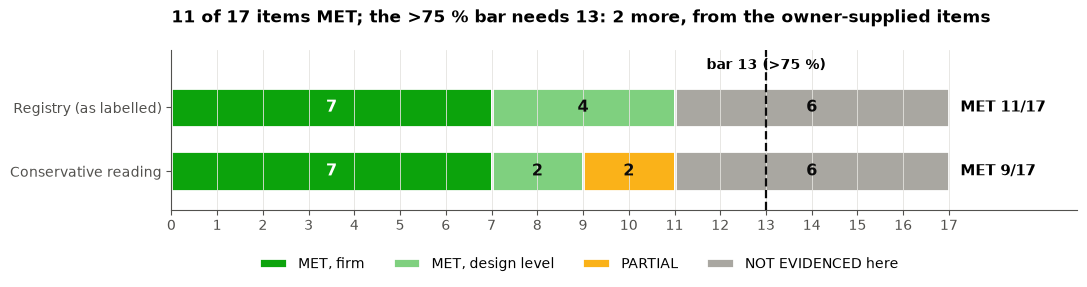

question,answer,status
Counts as labelled,"MET 11, PARTIAL 0, NOT MET 0, NOT EVIDENCED 6 of 17",-
"HONEST TALLY: firm (rank >= 6, no assumed/calculated leg)","7: C4, C5, S6, S7, S8, S9, IS3",MET
met at design level only (rank < 6 or an assumed/simulated leg),"4: S4, S5, IS1, IS2",MET
MET share vs the rubric (MORE THAN 75 % = >= 13 of 17),64.7 % -> NO,PARTIAL
Conservative reading (IS1 -> PARTIAL: Wi-Fi hop simulated; IS2 -> PARTIAL: wording v2 not yet confirmed by team/xlsx),MET 9 of 17 = 52.9 %,PARTIAL
Items still needed for >= 13,"2. Candidates: C1, C2, C6, S1, S2, S3 (NOT EVIDENCED; each needs the owner's artifact, section 12)",PARTIAL
ICS department (1 constraint + 2 specs),constraint C5: MET [MEASURED host]; spec S7: MET [SYNTHETIC]; spec S8: MET [MEASURED host] -> ALL MET,MET
Model change (approved),"N-HiTS/TFT -> gradient-boosted heads. Spec-named models kept for transparency: N-HiTS S7 46.9 %, TFT stage max error 3, TFT p95 1.54 ms.",-
Other ICS-related items,S9 MET [MEASURED host] | IS1 MET [SIMULATION] | IS3 MET [SYNTHETIC] | IS2 MET [SYNTHETIC]+[SIMULATION] under wording v2 (pending team/xlsx confirmation),-
Old (PPR) MET -> now MET,"['C4', 'C5', 'S8', 'S9'] -> ['C4', 'C5', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'IS1', 'IS2', 'IS3']",-


ID,Item,Owner dept,PPR status (old),UP2 status,Measured,Target,Verdict / note,Model actually deployed,"Spec-named model (N-HiTS/TFT), same data",Firm?,Rank achieved,Rank achievable,Step that raises it,Provenance,Source
C1,"OH-2 (API 610) pumps, Goulds 3196 STi+MTi class: drivers <=40/~122 HP, 1750/3500 rpm, housing <=10 mm/s RMS",ME,NOT EVIDENCED,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),-,see Specifications.md,"Target-machine envelope: datasheet table of the Goulds 3196 STi/MTi HP and rpm limits, CAD of the sensor mounting on the housing, a vibration-envelope check (<=10 mm/s RMS housing). [CITED] datasheet + CAD = Rank 3; sensor mounted on a pump/rig = Rank 9.",-,-,no,0,3-9 depending on the owner's artifact,"Target-machine envelope: datasheet table of the Goulds 3196 STi/MTi HP and rpm limits, CAD of the sensor mounting on the housing, a vibration-envelope check (<=10 mm/s RMS housing). [CITED] datasheet + CAD = Rank 3; sensor mounted on a pump/rig = Rank 9.",-,-
C2,"Mains-powered node; SELV (<=50 V DC) IEPE excitation 24 V/4 mA over coax, AC-coupled to ADC range",COE,NOT EVIDENCED,NOT EVIDENCED HERE - evidence to be supplied by owner (COE),-,see Specifications.md,Power-tree schematic or calculation: mains adapter -> SELV <=50 V DC; IEPE 24 V / 4 mA constant-current source over coax with AC coupling into the AD7606 range; ideally a bench photo with a meter reading.,-,-,no,0,3-9 depending on the owner's artifact,Power-tree schematic or calculation: mains adapter -> SELV <=50 V DC; IEPE 24 V / 4 mA constant-current source over coax with AC coupling into the AD7606 range; ideally a bench photo with a meter reading.,-,-
C4,"All real-time DAQ and signal processing run on local hardware, no cloud reliance",COE (counted for ICS),MET,MET [MEASURED host],120 windows classified + RUL with all network calls blocked (DNS lookup raised),no cloud reliance,COE-assigned in the sheet; counted for ICS by team decision 2026-10-05. DAQ+DSP part = simulated COE pipeline running locally (S4-S6),-,-,yes,7,9,Repeat with the real node and a physically disconnected uplink,[MEASURED host] (network-denied Python run),live: up2_helpers.c4_no_network_live
C5,Dashboard accessible only on the local network; no external/cloud exposure of vibration data,ICS,MET,MET [MEASURED host],"19/19 LanOnlyTests+UdpLanGuardTests pass (public HTTP clients 403, public UDP senders dropped)",LAN only,"guard unit tests + Kestrel bind; the network-denied run covers the Python inference path, not the C# backend",-,-,yes,9,9,Show a phone on the room Wi-Fi reaching the dashboard and a non-private client refused,[MEASURED host],live: dotnet test tests/DigitalTwin.Backend.Tests
C6,Enclosure from UV-stabilized weather-resistant polymer (ABS/PETG),ME,NOT EVIDENCED,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),-,see Specifications.md,Material datasheets (UV-stabilized ABS/PETG grade) and the enclosure photo or CAD with the material callout.,-,-,no,0,3-9 depending on the owner's artifact,Material datasheets (UV-stabilized ABS/PETG grade) and the enclosure photo or CAD with the material callout.,-,-
S1,"2x biaxial IEPE sets (4 ch): 100 mV/g, +-50 g, flat 2-10 kHz (off-the-shelf)",ME,NOT EVIDENCED,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),-,see Specifications.md,"Accelerometer datasheet (100 mV/g, +-50 g, flat 2-10 kHz) plus the purchase record; best: the 4 sensors on a shaker/pump with a measured sensitivity.",-,-,no,0,3-9 depending on the owner's artifact,"Accelerometer datasheet (100 mV/g, +-50 g, flat 2-10 kHz) plus the purchase record; best: the 4 sensors on a shaker/pump with a measured sensitivity.",-,-
S2,"FE digital twin identifies bearing stiffness K, <=10 % error vs known-stiffness reference",ME,NOT EVIDENCED,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),"precursor, NOT counted: 1750 rpm noisy mean err 6.4 %, p95 13.6 %, max 15.5 %; 3600 rpm mean 24.2 % [SIMULATION]",see Specifications.md,"FE beam model: stiffness id

master table saved: evidence\up2_figures\up2_master_table.csv
notebook run time: 382 s


In [22]:
M = U.master_frame()
cnt = U.verdict_counts(M)
cons = M.copy(); cons.loc[cons.ID == "IS1", "UP2 status"] = "PARTIAL (Wi-Fi hop simulated)"
cons.loc[cons.ID == "IS2", "UP2 status"] = "PARTIAL (wording v2 unconfirmed)"; c2 = U.verdict_counts(cons)
update_display(U.kpi_banner(M, c2["MET"]), display_id="kpi")
update_display(U.styled_scorecard(), display_id="scorecard")
update_display(U.styled_ppr_vs_up2(), display_id="pprup2")
display(U.kpi_banner(M, c2["MET"]))
chart(U.fig_status_summary, "up2_status_summary.png", M, cons)
s = M.set_index("ID")["UP2 status"]
ics = {"constraint C5": s["C5"], "spec S7": s["S7"], "spec S8": s["S8"]}
ok = all(v.startswith("MET") for v in ics.values())
need = max(0, cnt["bar"] - cnt["MET"])
firm_ids = list(M[(M['UP2 status'].str.startswith('MET')) & (M['Firm?'] == 'yes')].ID)
des_ids = list(M[(M['UP2 status'].str.startswith('MET')) & (M['Firm?'] != 'yes')].ID)
tally = pd.DataFrame([
    {"question": "Counts as labelled", "answer": ", ".join(f"{k} {cnt[k]}" for k in ("MET", "PARTIAL", "NOT MET", "NOT EVIDENCED")) + f" of {cnt['total']}", "status": "-"},
    {"question": "HONEST TALLY: firm (rank >= 6, no assumed/calculated leg)", "answer": f"{cnt['firm']}: {', '.join(firm_ids)}", "status": "MET"},
    {"question": "met at design level only (rank < 6 or an assumed/simulated leg)", "answer": f"{cnt['design_level']}: {', '.join(des_ids)}", "status": "MET"},
    {"question": f"MET share vs the rubric (MORE THAN 75 % = >= {cnt['bar']} of {cnt['total']})", "answer": f"{cnt['pct_met']:.1f} % -> {'YES' if cnt['gt75'] else 'NO'}", "status": "MET" if cnt["gt75"] else "PARTIAL"},
    {"question": "Conservative reading (IS1 -> PARTIAL: Wi-Fi hop simulated; IS2 -> PARTIAL: wording v2 not yet confirmed by team/xlsx)", "answer": f"MET {c2['MET']} of 17 = {c2['pct_met']:.1f} %", "status": "PARTIAL"},
    {"question": f"Items still needed for >= {cnt['bar']}", "answer": f"{need}. Candidates: C1, C2, C6, S1, S2, S3 (NOT EVIDENCED; each needs the owner's artifact, section 12)", "status": "MET" if need == 0 else "PARTIAL"},
    {"question": "ICS department (1 constraint + 2 specs)", "answer": "; ".join(f"{k}: {v}" for k, v in ics.items()) + (" -> ALL MET" if ok else " -> NOT ALL MET"), "status": "MET" if ok else "NOT MET"},
    {"question": "Model change (approved)", "answer": "N-HiTS/TFT -> gradient-boosted heads. Spec-named models kept for transparency: N-HiTS S7 %.1f %%, TFT stage max error %s, TFT p95 %.2f ms." % (SN.get("S7", float("nan")), SN.get("stage_max"), SN.get("tft_p95", float("nan"))), "status": "-"},
    {"question": "Other ICS-related items", "answer": f"S9 {s['S9']} | IS1 {s['IS1']} | IS3 {s['IS3']} | IS2 {s['IS2']}", "status": "-"},
    {"question": "Old (PPR) MET -> now MET", "answer": f"{[i for i, _, _, p in U.ITEMS if p == 'MET']} -> {list(s[s.str.startswith('MET')].index)}", "status": "-"},
    {"question": "C3 (BOM cost)", "answer": "EXCLUDED by the reviewer, not counted", "status": "-"},
    {"question": "IS2 v1 literal values by set (history)", "answer": "test2 tuned filter 302 % [section 10b]; test4 deployed v3b 233 % [section 10]", "status": "NOT MET"},
])
display(U.table(tally, status_cols=["status"], caption="Honest tally (computed from the registry)"))
M.to_csv(FIG / "up2_master_table.csv", index=False)
Mx = M.copy(); Mx["Rank achieved"] = Mx["Rank achieved"].astype(str)
display(U.details("MASTER TABLE: all columns for the 17 counted items (verdict notes, deployed vs spec-named model, rank achievable, next step, source)",
                  body_html=U.table(Mx, status_cols=["UP2 status", "PPR status (old)"]).set_properties(**{"white-space": "pre-wrap"}).to_html(), open_=False))
print("master table saved:", (FIG / "up2_master_table.csv").relative_to(U.REPO))
print(f"notebook run time: {time.time()-T_START:.0f} s")

## Additional items with supporting evidence (not counted; for the reviewer's judgement)

Nothing below changes a status or a rank in the master table.

### A. COE-integration readiness: the domain gap and its adaptation

The deployed v3b classifier was trained on payload-level synthetic features. The COE pipeline (the code that becomes the STM32 firmware)
produces its own features from raw samples, so the models were tested on **raw samples from the COE rig simulator through the real causal
`CoePipeline`** (dataset `synth_coe`, 420 runs, split by run; the 106-run COE-test scored once). The cell re-scores the **saved** COE-test
predictions with the logic of `python -m aiengine.coe_adapt_eval` (no retraining, no new report). `[SIMULATION]` + `[SYNTHETIC]`.

classifier,macro-F1,B2 false-fault %,B1 false-fault %,both-healthy false-fault %,missed-fault %,wrong-class %,F1 cage
v3b as deployed,0.584,82.051,74.652,0.075,2.175,28.617,0.242
"adapted, no gate (ablation: retrain alone)",0.777,52.962,39.487,0.000,15.408,3.800,0.792
deployed + gate (ablation: gate alone),0.725,4.421,2.637,0.037,13.897,19.528,0.246
SELECTED: adapted + gate,0.875,0.619,0.000,0.000,22.825,0.160,0.828


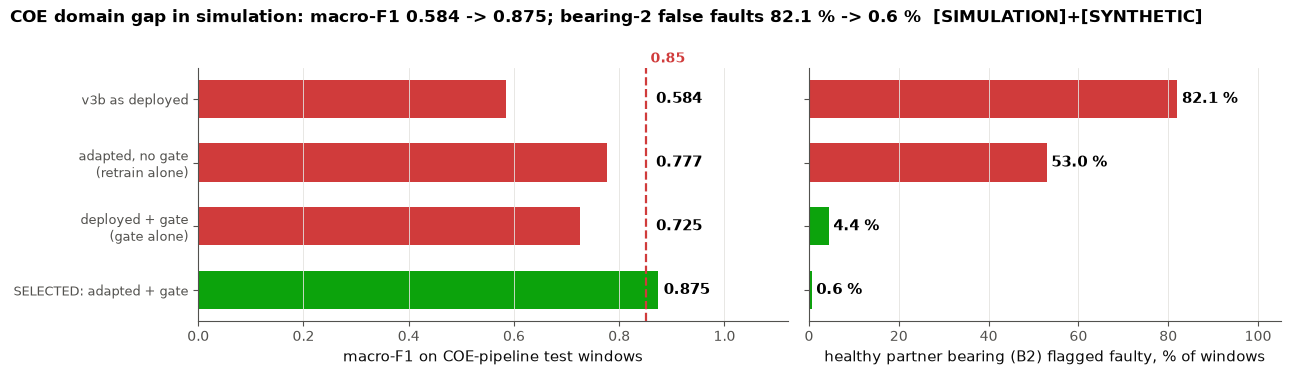

In [23]:
CA = U.coe_adapt_rescore()
if CA["status"] == "ok":
    t0 = CA["table"]; sm = CA["sel_metrics"]
    display(U.verdict("COE adaptation", bool(sm) and sm["classification"]["macro_f1"] >= .85,
                      f"macro-F1 {t0.iloc[0]['macro-F1']:.3f} -> {sm['classification']['macro_f1']:.3f}; bearing-2 false-fault {t0.iloc[0]['B2 false-fault %']:.1f} % -> {100*sm['b2_transmitted_false_fault_rate']:.1f} % (readiness only, not counted)" if sm else "selected model metrics missing",
                      "[SIMULATION] [SYNTHETIC]"))
    display(U.table(t0, precision=3, caption=f"COE-test re-score: {CA['index']} (scored once {CA['scored_utc']}); {CA['n_runs_test']} runs, {CA['windows']} bearing-windows; selected {CA['selected']}"))
    chart(U.fig_coe_adapt, "coe_adapt.png", t0)
    display(U.details("Limitations and what to re-fit on hardware day", body_md=f"""
- Stage/RUL heads on COE features: healthy bearings at raw stage >= 2 in {100*CA['rul_diag']['healthy_stage_raw_ge2_rate']:.0f} % of {CA['rul_diag']['healthy_windows']} windows -> **NOT reliable on COE features** (needs COE run-to-failure data).
- The missed-fault rate rises to {100*sm['missed_fault_rate']:.1f} % because the gate trades recall at low severity (<= 0.2) for removing the false alarms on the partner bearing (cage F1 {sm['classification']['per_class_f1']['cage']:.2f}).
- The COE runs are not run-to-failure, so no RUL or stage truth exists there. The simulator's partner-transmission gain is invented, so `tau` is a placeholder. None of this validates real hardware.
- **Hardware day:** re-fit the gate threshold `tau` (commissioning data with a known-healthy partner), the stage cut and the classifier with real seeded faults; then re-score S7/IS3 on rig windows. The adapted classifier and contract are `models/v3b_coe_cls.onnx` / `model_contract_v3b_coe.json` for COE-pipeline sources (the deployed v3b contract is unchanged).
""" if sm else "selected metrics missing"))
else:
    display(U.missing(CA))

### B. Proposed wireless-link reliability constraint (not one of the 17)

C6 of the spec sheet is the ENCLOSURE (ME). The wireless-link reliability constraint COE simulated is a **proposed extra**, shown for information only.

In [24]:
c6 = (coe_st or {}).get("C6")
if c6:
    okl = c6["window_loss_pct"]["end_to_end"] <= 1
    display(U.verdict("proposed link constraint", okl, f"end-to-end window loss {c6['window_loss_pct']['end_to_end']} % (limit 1 %) under ASSUMED loss rates; not counted", "[SIMULATION]", note=f"{c6['verdict']} | source {U.stamp(coe_p)}"))
else:
    display(U.missing("coe_verification.json C6 block"))

## What is met, what is not, and why

In [25]:
s = M.set_index("ID")
def ids(f): return [i for i in s.index if f(i)]
firm = ids(lambda i: U.kind(s.loc[i, "UP2 status"]) == "MET" and s.loc[i, "Firm?"] == "yes")
des = ids(lambda i: U.kind(s.loc[i, "UP2 status"]) == "MET" and s.loc[i, "Firm?"] != "yes")
noev = ids(lambda i: U.kind(s.loc[i, "UP2 status"]) == "NOT EVIDENCED")
notmet = ids(lambda i: U.kind(s.loc[i, "UP2 status"]) in ("NOT MET", "PARTIAL"))
def line(i): return f"**{i}** ({U.SHORT.get(i, '')}): {s.loc[i, 'Measured']}"
txt = ("**Met, firm** (" + ", ".join(firm) + "):\n" + "\n".join(f"- {line(i)}" for i in firm)
       + "\n\n**Met at design level** (" + ", ".join(des) + "), counted but flagged:\n" + "\n".join(f"- {line(i)}. *Why design level:* " + {"S4": "calculation + a non-falsifiable simulation (Rank 3)", "S5": "host time is not STM32 time; the STM32 leg is calculated", "IS1": "the Wi-Fi hop is simulated and the STM32 leg calculated", "IS2": "wording v2 is not yet in the official xlsx; clause (a) mostly measures agreement with the twin's prior"}.get(i, "assumed leg") for i in des)
       + ("\n\n**Not met:** " + ", ".join(notmet) if notmet else "\n\n**Not met:** none in the registry (IS2 under the literal v1 wording and the public-data S7/IS3 numbers remain FAIL as history).")
       + "\n\n**Not evidenced here** (" + ", ".join(noev) + "): owners supply the artifact (section 12); none is counted.\n\n"
       + f"**Bar:** {len(firm) + len(des)} of 17 MET, the rubric needs {U.BAR}. The ICS block (C5, S7, S8) is all met. "
       + "**Next steps:** owners' evidence for C1, C2, C6, S1, S2, S3; team pastes IS2 wording v2 into the xlsx and tells the coach the clause-(a) caveat; "
       + "on hardware day measure the Wi-Fi hop, the STM32 leg and the browser update, and re-fit the classifier, stage cut and gate on rig data.")
display(Markdown(txt))

**Met, firm** (C4, C5, S6, S7, S8, S9, IS3):
- **C4** (Local processing, no cloud): 120 windows classified + RUL with all network calls blocked (DNS lookup raised)
- **C5** (Dashboard on the LAN only): 19/19 LanOnlyTests+UdpLanGuardTests pass (public HTTP clients 403, public UDP senders dropped)
- **S6** (Fixed-dim AI input, 1000-3600 rpm): 28 speeds 1000-3600 rpm -> all (32,) features / 152 B, finite
- **S7** (RUL MAPE <= 15 %): 12.64 % MAPE (strict-onset variant 14.72 %)
- **S8** (Classification < 200 ms/window): p95 0.553 ms (engine step p95 5.20 ms)
- **S9** (Dashboard >= 10 Hz): 30.0 Hz client rate; worst 1-s window 29
- **IS3** (macro-F1 >= 0.85, stage err <= 1, caught by stage 3): F1 0.959; stage max 1; caught 80/80

**Met at design level** (S4, S5, IS1, IS2), counted but flagged:
- **S4** (Sample rate >= 25 kS/s/ch x 4): 30 kS/s/ch x 4 ch, gap-free sim, 16.3 us slack. *Why design level:* calculation + a non-falsifiable simulation (Rank 3)
- **S5** (Window -> payload <= 333 ms): host worst 7.76 ms; STM32 pessimistic calc 28.4 ms. *Why design level:* host time is not STM32 time; the STM32 leg is calculated
- **IS1** (Sensor -> dashboard < 500 ms): p95 97.9 ms, max 104.9 ms (STM32-pessimistic COE + simulated Wi-Fi 10-60 ms + measured backend). *Why design level:* the Wi-Fi hop is simulated and the STM32 leg calculated
- **IS2** (Physics-AI RUL agreement): v2: median 16.3 % (<=18), p95 49.2 % (<=63) of L_ref; v1 literal max 233 % (FAIL, history); v3c research median 18.3 % FAIL. *Why design level:* wording v2 is not yet in the official xlsx; clause (a) mostly measures agreement with the twin's prior

**Not met:** none in the registry (IS2 under the literal v1 wording and the public-data S7/IS3 numbers remain FAIL as history).

**Not evidenced here** (C1, C2, C6, S1, S2, S3): owners supply the artifact (section 12); none is counted.

**Bar:** 11 of 17 MET, the rubric needs 13. The ICS block (C5, S7, S8) is all met. **Next steps:** owners' evidence for C1, C2, C6, S1, S2, S3; team pastes IS2 wording v2 into the xlsx and tells the coach the clause-(a) caveat; on hardware day measure the Wi-Fi hop, the STM32 leg and the browser update, and re-fit the classifier, stage cut and gate on rig data.